In [30]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

data_file = (
    project_dir / "data" / "processed" / "route_features.csv"
)

df = pd.read_csv(data_file)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 8322
Columns: 20


,route_id,route_short_name,route_long_name,route_type,scheduled_trip_count,stop_count,estimated_straight_line_route_km,trips_with_distance,operates_monday,operates_tuesday,operates_wednesday,operates_thursday,operates_friday,operates_saturday,operates_sunday,operating_day_count,city,start_service_hour,end_service_hour,trips_with_valid_departure
0,101sh,101sh,P.D.P.U. Cross Road ⇆ Asarva Railway Station,3,10,44,44.528570,10.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,6.0,19.0,10
1,103-1,103,Bhakti Circle ⇆ Gujarat University,3,22,80,22.365598,22.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,6.0,21.0,22
2,103-2,103,Bhakti Circle ⇆ Sarangpur,3,14,52,14.922204,14.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,5.0,23.0,14
3,103-3,103,Gujarat University ⇆ Sarangpur,3,6,28,8.947943,6.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,12.0,22.0,6
4,105,105,Naroda Industrial Township( MuthiyaGam ) ⇆ Lal...,3,216,40,63.726733,216.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,5.0,23.0,216


In [31]:
# ROUTERANKER - MODULE 3
# Step 2: Data Quality Check

print("DATA QUALITY SUMMARY")
print("-" * 40)

print("Dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values by column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nSummary statistics:")
display(df.describe().round(2))

DATA QUALITY SUMMARY
----------------------------------------
Dataset shape: (8322, 20)
Duplicate rows: 0

Missing values by column:


,Missing Values
route_id,0
route_short_name,1031
route_long_name,0
route_type,0
scheduled_trip_count,0
stop_count,0
estimated_straight_line_route_km,1010
trips_with_distance,1010
operates_monday,1006
operates_tuesday,1006



Data types:


,Data Type
route_id,str
route_short_name,str
route_long_name,str
route_type,int64
scheduled_trip_count,int64
stop_count,int64
estimated_straight_line_route_km,float64
trips_with_distance,float64
operates_monday,float64
operates_tuesday,float64



Summary statistics:


,route_type,scheduled_trip_count,stop_count,estimated_straight_line_route_km,trips_with_distance,operates_monday,operates_tuesday,operates_wednesday,operates_thursday,operates_friday,operates_saturday,operates_sunday,operating_day_count,start_service_hour,end_service_hour,trips_with_valid_departure
count,8322.00,8322.00,8322.00,7312.00,7312.00,7316.00,7316.00,7316.00,7316.00,7316.00,7316.00,7316.00,7316.00,7316.00,7316.00,8322.00
mean,2.81,26.06,31.18,21.55,29.66,0.98,0.98,0.98,0.98,0.98,0.98,0.97,6.82,8.33,21.12,26.06
std,0.59,75.38,32.42,19.02,79.75,0.15,0.15,0.15,0.15,0.15,0.15,0.17,0.94,5.40,13.12,75.38
min,1.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00
25%,3.00,1.00,12.00,9.72,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,7.00,5.00,15.00,1.00
50%,3.00,4.00,24.00,17.95,5.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,7.00,6.00,20.00,4.00
75%,3.00,15.00,40.00,28.19,20.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,7.00,11.00,23.00,15.00
max,3.00,2087.00,795.00,715.65,2087.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,7.00,34.00,311.00,2087.00


CITY-WISE ROUTE COMPARISON


,total_routes,total_scheduled_trips,average_trips_per_route,average_stops
city,,,,
ahmedabad,639,14323,22.41,40.27
chennai,5402,48435,8.97,20.82
hyderabad,1031,44892,43.54,63.86
mumbai,935,99080,105.97,31.59
pune,315,10128,32.15,82.09


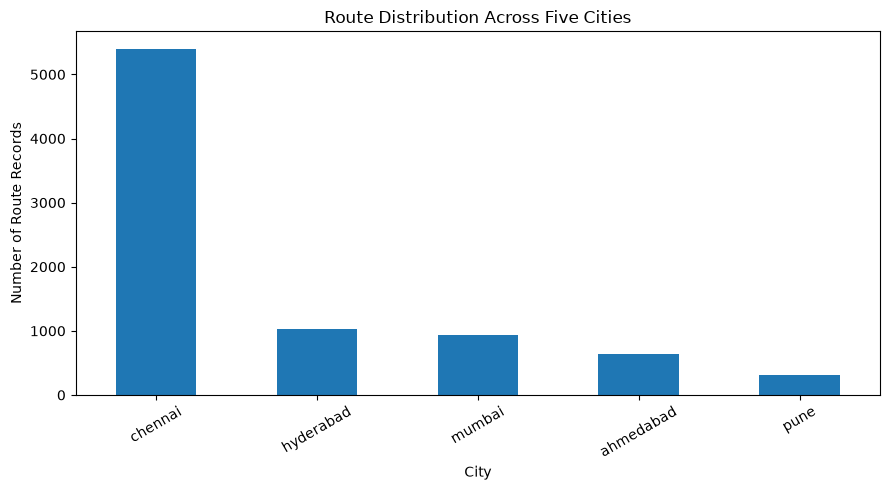

In [32]:
# ROUTERANKER - MODULE 3
# Step 3: City-wise Route Analysis

city_summary = df.groupby("city").agg(
    total_routes=("route_id", "count"),
    total_scheduled_trips=("scheduled_trip_count", "sum"),
    average_trips_per_route=("scheduled_trip_count", "mean"),
    average_stops=("stop_count", "mean")
).round(2)

print("CITY-WISE ROUTE COMPARISON")
display(city_summary)

# Bar chart: Number of route records per city
city_summary["total_routes"].sort_values(
    ascending=False
).plot(
    kind="bar",
    figsize=(9, 5),
    title="Route Distribution Across Five Cities",
    xlabel="City",
    ylabel="Number of Route Records",
    rot=30
)

plt.tight_layout()
plt.show()

SCHEDULED TRIPS ANALYSIS
----------------------------------------
Scheduled trips summary:


,scheduled_trip_count
count,8322.00
mean,26.06
std,75.38
min,0.00
25%,1.00
50%,4.00
75%,15.00
max,2087.00


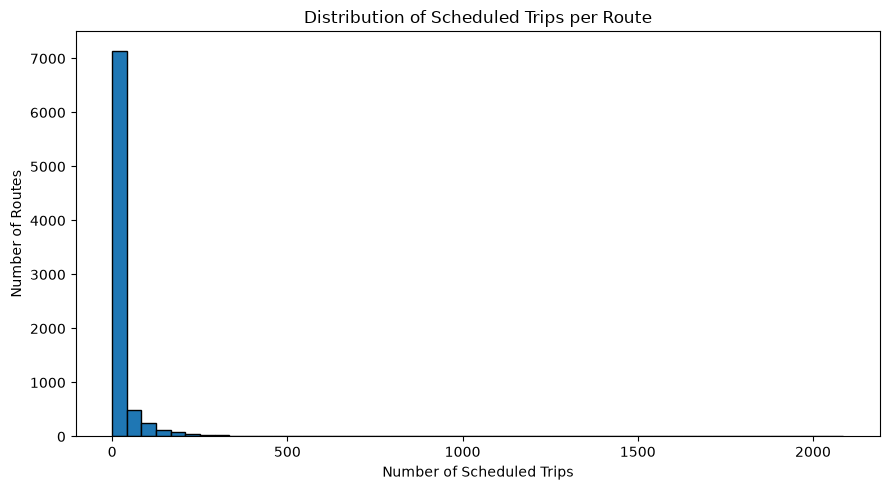

In [33]:
# ROUTERANKER - MODULE 3
# Step 4: Scheduled Trips Analysis

print("SCHEDULED TRIPS ANALYSIS")
print("-" * 40)

print("Scheduled trips summary:")
display(df["scheduled_trip_count"].describe().to_frame().round(2))

# Distribution of scheduled trips per route
plt.figure(figsize=(9, 5))

plt.hist(
    df["scheduled_trip_count"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Scheduled Trips per Route")
plt.xlabel("Number of Scheduled Trips")
plt.ylabel("Number of Routes")
plt.tight_layout()
plt.show()

AVERAGE SCHEDULED TRIPS PER ROUTE BY CITY


,Average Scheduled Trips per Route
city,
mumbai,105.97
hyderabad,43.54
pune,32.15
ahmedabad,22.41
chennai,8.97


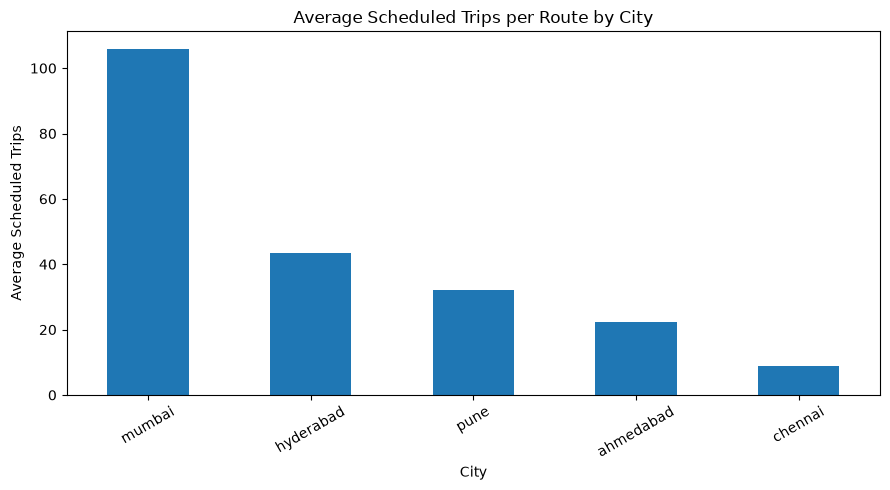

In [34]:
# ROUTERANKER - MODULE 3
# Step 4B: City-wise Average Scheduled Trips

avg_trips = (
    df.groupby("city")["scheduled_trip_count"]
    .mean()
    .sort_values(ascending=False)
)

print("AVERAGE SCHEDULED TRIPS PER ROUTE BY CITY")
display(
    avg_trips.to_frame(
        "Average Scheduled Trips per Route"
    ).round(2)
)

avg_trips.plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Scheduled Trips per Route by City",
    xlabel="City",
    ylabel="Average Scheduled Trips",
    rot=30
)

plt.tight_layout()
plt.show()

ROUTE STOPS AND DISTANCE ANALYSIS
---------------------------------------------

Stop count summary:


,stop_count
count,8322.00
mean,31.18
std,32.42
min,0.00
25%,12.00
50%,24.00
75%,40.00
max,795.00



Estimated route distance summary (km):


,estimated_straight_line_route_km
count,7312.00
mean,21.55
std,19.02
min,0.00
25%,9.72
50%,17.95
75%,28.19
max,715.65


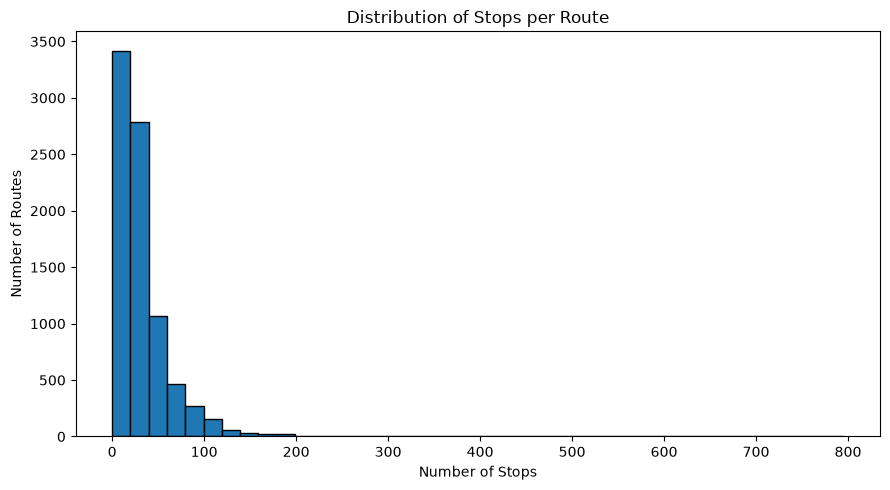

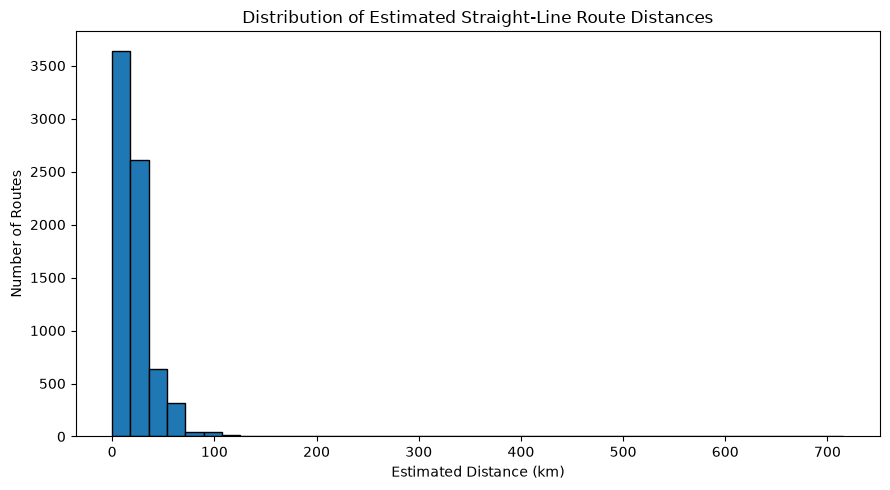

In [35]:
# ROUTERANKER - MODULE 3
# Step 5: Route Stops and Distance Analysis

print("ROUTE STOPS AND DISTANCE ANALYSIS")
print("-" * 45)

print("\nStop count summary:")
display(df["stop_count"].describe().round(2).to_frame())

print("\nEstimated route distance summary (km):")
display(
    df["estimated_straight_line_route_km"]
    .describe()
    .round(2)
    .to_frame()
)

# Chart 1: Distribution of stop counts
plt.figure(figsize=(9, 5))
plt.hist(df["stop_count"], bins=40, edgecolor="black")
plt.title("Distribution of Stops per Route")
plt.xlabel("Number of Stops")
plt.ylabel("Number of Routes")
plt.tight_layout()
plt.show()

# Chart 2: Distribution of estimated distances
distance_data = df["estimated_straight_line_route_km"].dropna()

plt.figure(figsize=(9, 5))
plt.hist(distance_data, bins=40, edgecolor="black")
plt.title("Distribution of Estimated Straight-Line Route Distances")
plt.xlabel("Estimated Distance (km)")
plt.ylabel("Number of Routes")
plt.tight_layout()
plt.show()

CITY-WISE ROUTE CHARACTERISTICS


,average_stops,median_stops,average_distance_km,median_distance_km
city,,,,
ahmedabad,40.27,37.0,24.83,16.61
chennai,20.82,19.0,21.42,18.03
hyderabad,63.86,55.0,25.95,21.87
mumbai,31.59,21.0,12.25,8.86
pune,82.09,79.0,20.54,18.21


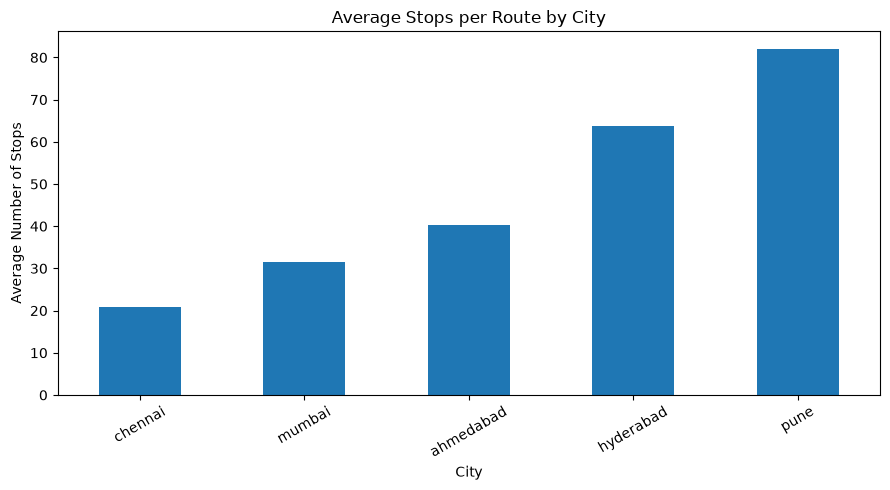

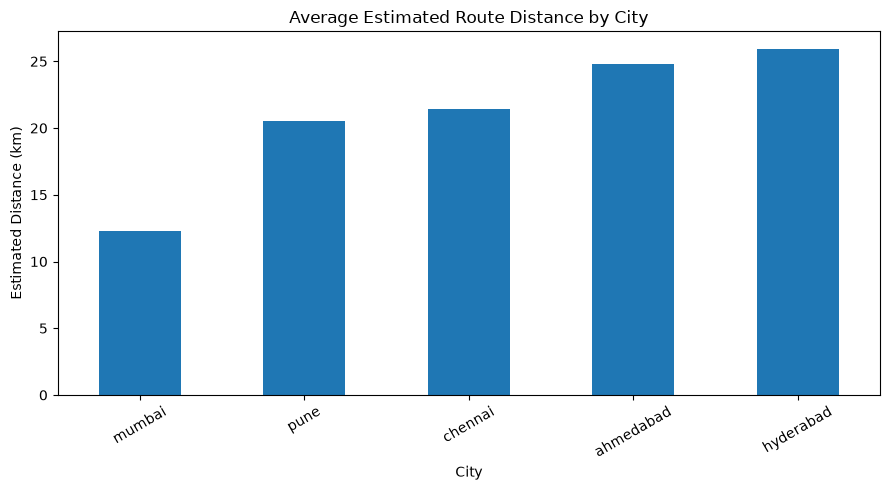

In [36]:
# ROUTERANKER - MODULE 3
# Step 6: City-wise Route Characteristics

city_characteristics = df.groupby("city").agg(
    average_stops=("stop_count", "mean"),
    median_stops=("stop_count", "median"),
    average_distance_km=(
        "estimated_straight_line_route_km", "mean"
    ),
    median_distance_km=(
        "estimated_straight_line_route_km", "median"
    )
).round(2)

print("CITY-WISE ROUTE CHARACTERISTICS")
display(city_characteristics)

# Compare average stops
city_characteristics["average_stops"].sort_values().plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Stops per Route by City",
    xlabel="City",
    ylabel="Average Number of Stops",
    rot=30
)

plt.tight_layout()
plt.show()

# Compare average estimated distances
city_characteristics["average_distance_km"].sort_values().plot(
    kind="bar",
    figsize=(9, 5),
    title="Average Estimated Route Distance by City",
    xlabel="City",
    ylabel="Estimated Distance (km)",
    rot=30
)

plt.tight_layout()
plt.show()

In [37]:
# ROUTERANKER - MODULE 3
# Step 7: Service Hour Analysis

print("SERVICE HOUR ANALYSIS")
print("-" * 40)

print("Start service hour summary:")
display(df["start_service_hour"].describe().to_frame().round(2))

print("\nEnd service hour summary:")
display(df["end_service_hour"].describe().to_frame().round(2))

# Check unusual service-hour values
print("\nRoutes with start hours outside 0-23:")
display(
    df.loc[
        (df["start_service_hour"] < 0) |
        (df["start_service_hour"] > 23),
        ["city", "route_id", "start_service_hour"]
    ].head(20)
)

print("\nRoutes with end hours outside 0-23:")
display(
    df.loc[
        (df["end_service_hour"] < 0) |
        (df["end_service_hour"] > 23),
        ["city", "route_id", "end_service_hour"]
    ].head(20)
)

SERVICE HOUR ANALYSIS
----------------------------------------
Start service hour summary:


,start_service_hour
count,7316.00
mean,8.33
std,5.40
min,0.00
25%,5.00
50%,6.00
75%,11.00
max,34.00



End service hour summary:


,end_service_hour
count,7316.00
mean,21.12
std,13.12
min,0.00
25%,15.00
50%,20.00
75%,23.00
max,311.00



Routes with start hours outside 0-23:


,city,route_id,start_service_hour
6067,hyderabad,104R/102,28.0
6122,hyderabad,115C,34.0
6190,hyderabad,16C/281,31.0
6321,hyderabad,1Z/95K,29.0
6327,hyderabad,201G/H,28.0
6329,hyderabad,201H/G,29.0
6346,hyderabad,203AK/102B,29.0
6478,hyderabad,230T,30.0
6563,hyderabad,25P,32.0
6571,hyderabad,26S,32.0



Routes with end hours outside 0-23:


,city,route_id,end_service_hour
55,ahmedabad,14-1,45.0
60,ahmedabad,142-1,70.0
66,ahmedabad,144/1-1,24.0
82,ahmedabad,150-2,24.0
97,ahmedabad,204,45.0
98,ahmedabad,205,43.0
117,ahmedabad,31/5-1,24.0
137,ahmedabad,40/2-1,71.0
139,ahmedabad,40/2-3,66.0
156,ahmedabad,51T-1,45.0


In [38]:
# ROUTERANKER - MODULE 3
# Step 8: Investigate Service-Hour Anomalies

valid_hours = df[
    ["start_service_hour", "end_service_hour"]
].notna().all(axis=1)

hour_anomalies = df.loc[
    valid_hours
    & (
        (df["start_service_hour"] > 23)
        | (df["end_service_hour"] > 23)
    )
]

print("SERVICE-HOUR ANOMALY SUMMARY")
print("-" * 40)

print("Routes with service hours above 23:",
      len(hour_anomalies))

print("\nAnomalies by city:")
display(
    hour_anomalies.groupby("city")
    .size()
    .to_frame("Routes with Hours Above 23")
)

print("\nHighest service-hour values:")
display(
    hour_anomalies[
        [
            "city",
            "route_id",
            "start_service_hour",
            "end_service_hour"
        ]
    ]
    .sort_values("end_service_hour", ascending=False)
    .head(15)
)


SERVICE-HOUR ANOMALY SUMMARY
----------------------------------------
Routes with service hours above 23: 1208

Anomalies by city:


,Routes with Hours Above 23
city,
ahmedabad,21
chennai,84
hyderabad,884
mumbai,208
pune,11



Highest service-hour values:


,city,route_id,start_service_hour,end_service_hour
6698,hyderabad,300,3.0,311.0
6850,hyderabad,500,5.0,158.0
6110,hyderabad,113M/217,4.0,140.0
6761,hyderabad,416,6.0,140.0
6862,hyderabad,532,4.0,129.0
6160,hyderabad,156/505,9.0,123.0
6795,hyderabad,459,5.0,120.0
6162,hyderabad,156H/217,4.0,114.0
6699,hyderabad,300/118W,14.0,110.0
6857,hyderabad,524,5.0,109.0


CORRELATION MATRIX


,scheduled_trip_count,stop_count,estimated_straight_line_route_km,trips_with_distance,operating_day_count,start_service_hour,end_service_hour,trips_with_valid_departure
scheduled_trip_count,1.00,0.40,-0.11,1.00,0.07,-0.30,0.26,1.00
stop_count,0.40,1.00,0.29,0.38,0.08,-0.26,0.54,0.40
estimated_straight_line_route_km,-0.11,0.29,1.00,-0.11,-0.24,0.05,0.17,-0.11
trips_with_distance,1.00,0.38,-0.11,1.00,0.07,-0.30,0.26,1.00
operating_day_count,0.07,0.08,-0.24,0.07,1.00,-0.17,0.11,0.07
start_service_hour,-0.30,-0.26,0.05,-0.30,-0.17,1.00,0.00,-0.30
end_service_hour,0.26,0.54,0.17,0.26,0.11,0.00,1.00,0.26
trips_with_valid_departure,1.00,0.40,-0.11,1.00,0.07,-0.30,0.26,1.00


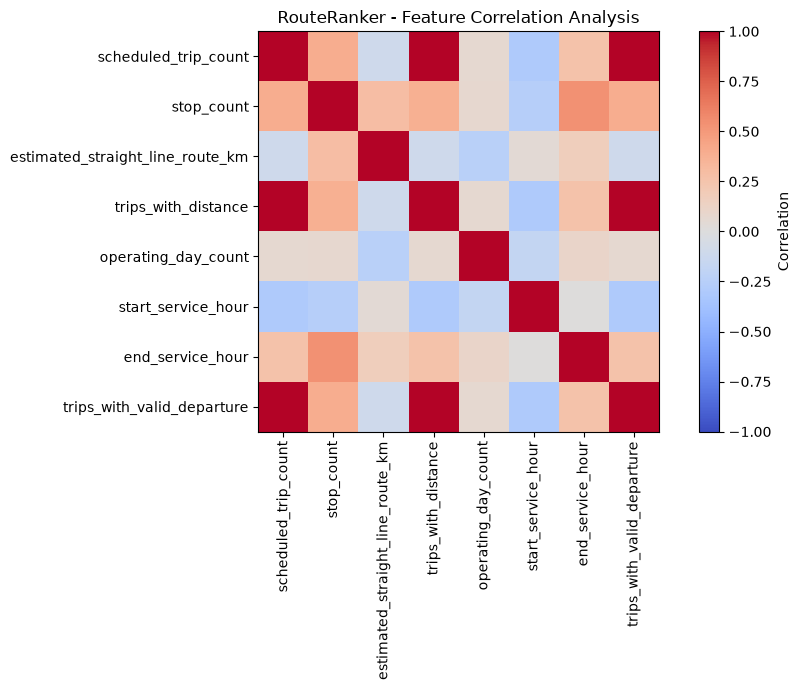

In [39]:
# ROUTERANKER - MODULE 3
# Step 9: Correlation Analysis

import matplotlib.pyplot as plt

features = [
    "scheduled_trip_count",
    "stop_count",
    "estimated_straight_line_route_km",
    "trips_with_distance",
    "operating_day_count",
    "start_service_hour",
    "end_service_hour",
    "trips_with_valid_departure"
]

correlation_matrix = df[features].corr()

print("CORRELATION MATRIX")
display(correlation_matrix.round(2))

plt.figure(figsize=(10, 7))

plt.imshow(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.colorbar(label="Correlation")
plt.xticks(
    range(len(features)),
    features,
    rotation=90
)
plt.yticks(range(len(features)), features)

plt.title("RouteRanker - Feature Correlation Analysis")
plt.tight_layout()
plt.show()

In [40]:
# ROUTERANKER - MODULE 3
# Step 10: Compare Trip-Count Features

trip_columns = [
    "scheduled_trip_count",
    "trips_with_distance",
    "trips_with_valid_departure"
]

print("TRIP-COUNT FEATURE COMPARISON")
print("-" * 40)

display(df[trip_columns].describe().round(2))

print(
    "Scheduled trips == trips with distance:",
    df["scheduled_trip_count"].equals(df["trips_with_distance"])
)

print(
    "Scheduled trips == valid departure trips:",
    df["scheduled_trip_count"].equals(df["trips_with_valid_departure"])
)

print(
    "Trips with distance == valid departure trips:",
    df["trips_with_distance"].equals(df["trips_with_valid_departure"])
)

TRIP-COUNT FEATURE COMPARISON
----------------------------------------


,scheduled_trip_count,trips_with_distance,trips_with_valid_departure
count,8322.00,7312.00,8322.00
mean,26.06,29.66,26.06
std,75.38,79.75,75.38
min,0.00,1.00,0.00
25%,1.00,1.00,1.00
50%,4.00,5.00,4.00
75%,15.00,20.00,15.00
max,2087.00,2087.00,2087.00


Scheduled trips == trips with distance: False
Scheduled trips == valid departure trips: True
Trips with distance == valid departure trips: False


In [41]:
# ROUTERANKER - MODULE 3
# Step 11: Check Trip-Count Differences

different = df[
    df["scheduled_trip_count"] != df["trips_with_distance"]
]

print("Rows with different trip counts:", len(different))

display(
    different[
        [
            "city",
            "route_id",
            "scheduled_trip_count",
            "trips_with_distance",
            "trips_with_valid_departure"
        ]
    ].head(10)
)

Rows with different trip counts: 1010


,city,route_id,scheduled_trip_count,trips_with_distance,trips_with_valid_departure
626,ahmedabad,Kalol To Pathikashram Via Sardhav,0,NaN,0
627,ahmedabad,Mansa To Pathikashram,0,NaN,0
631,ahmedabad,Pathikashram To Kalol Via Sardhav,0,NaN,0
632,ahmedabad,Pathikashram To Mansa,0,NaN,0
634,ahmedabad,Pathikashram To Pundhara,0,NaN,0
637,ahmedabad,Pundhara To Pathikashram,0,NaN,0
648,chennai,MTC-18761,0,NaN,0
650,chennai,MTC-11919,0,NaN,0
655,chennai,MTC-18763,0,NaN,0
658,chennai,MTC-13402,0,NaN,0


In [42]:
# ROUTERANKER - MODULE 3
# Step 12: Check Routes with Zero Scheduled Trips

zero_trip_routes = df[df["scheduled_trip_count"] == 0]

print("Routes with zero scheduled trips:", len(zero_trip_routes))

print("\nZero-trip routes by city:")
display(
    zero_trip_routes.groupby("city")
    .size()
    .to_frame("Zero-Trip Routes")
)

print("\nMissing distance counts:")
print(
    "Missing trips_with_distance:",
    df["trips_with_distance"].isna().sum()
)

print(
    "Zero-trip routes with missing distance:",
    zero_trip_routes["trips_with_distance"].isna().sum()
)

Routes with zero scheduled trips: 1006

Zero-trip routes by city:


,Zero-Trip Routes
city,
ahmedabad,6
chennai,677
mumbai,323



Missing distance counts:
Missing trips_with_distance: 1010
Zero-trip routes with missing distance: 1006


In [43]:
# ROUTERANKER - MODULE 3
# Step 13: Inspect Additional Missing Distance Values

additional_missing = df[
    df["trips_with_distance"].isna()
    & (df["scheduled_trip_count"] != 0)
]

print("Additional routes with missing distance counts:",
      len(additional_missing))

display(
    additional_missing[
        [
            "city",
            "route_id",
            "scheduled_trip_count",
            "stop_count",
            "estimated_straight_line_route_km",
            "trips_with_distance",
            "trips_with_valid_departure"
        ]
    ]
)

Additional routes with missing distance counts: 4


,city,route_id,scheduled_trip_count,stop_count,estimated_straight_line_route_km,trips_with_distance,trips_with_valid_departure
5965,chennai,SRR-43551,1,1,NaN,NaN,1
5966,chennai,SRR-43552,1,1,NaN,NaN,1
5967,chennai,SRR-43553,1,1,NaN,NaN,1
5968,chennai,SRR-43554,1,1,NaN,NaN,1


In [44]:
# ROUTERANKER - MODULE 3
# Step 14: Investigate Routes with Zero Stops

zero_stop_routes = df[df["stop_count"] == 0]

print("Routes with zero stops:", len(zero_stop_routes))

print("\nZero-stop routes by city:")
display(
    zero_stop_routes.groupby("city")
    .size()
    .to_frame("Zero-Stop Routes")
)

print("\nSample zero-stop routes:")
display(
    zero_stop_routes[
        [
            "city",
            "route_id",
            "scheduled_trip_count",
            "stop_count",
            "estimated_straight_line_route_km"
        ]
    ].head(10)
)

Routes with zero stops: 1006

Zero-stop routes by city:


,Zero-Stop Routes
city,
ahmedabad,6
chennai,677
mumbai,323



Sample zero-stop routes:


,city,route_id,scheduled_trip_count,stop_count,estimated_straight_line_route_km
626,ahmedabad,Kalol To Pathikashram Via Sardhav,0,0,NaN
627,ahmedabad,Mansa To Pathikashram,0,0,NaN
631,ahmedabad,Pathikashram To Kalol Via Sardhav,0,0,NaN
632,ahmedabad,Pathikashram To Mansa,0,0,NaN
634,ahmedabad,Pathikashram To Pundhara,0,0,NaN
637,ahmedabad,Pundhara To Pathikashram,0,0,NaN
648,chennai,MTC-18761,0,0,NaN
650,chennai,MTC-11919,0,0,NaN
655,chennai,MTC-18763,0,0,NaN
658,chennai,MTC-13402,0,0,NaN


In [45]:
# ROUTERANKER - MODULE 3
# Step 15: Investigate High Stop Counts

print("Top 15 routes by stop count:")

display(
    df[
        [
            "city",
            "route_id",
            "scheduled_trip_count",
            "stop_count",
            "estimated_straight_line_route_km"
        ]
    ]
    .sort_values("stop_count", ascending=False)
    .head(15)
)

Top 15 routes by stop count:


,city,route_id,scheduled_trip_count,stop_count,estimated_straight_line_route_km
6416,hyderabad,219,2087,795,29.926609
6698,hyderabad,300,1314,496,30.923426
6391,hyderabad,216,676,405,24.397854
6400,hyderabad,217,260,384,33.711431
6177,hyderabad,16A,439,349,12.402755
6596,hyderabad,277D,372,340,31.350970
6405,hyderabad,218,630,295,31.578290
6756,hyderabad,412,91,285,37.551130
6702,hyderabad,300/251,184,277,29.019914
6084,hyderabad,10H,1161,270,18.395407


In [46]:
# ROUTERANKER - MODULE 3
# Step 16: Stop Count Distribution for Active Routes

active_routes = df[df["scheduled_trip_count"] > 0]

print("Active routes:", len(active_routes))

print("\nStop-count summary for active routes:")
display(active_routes["stop_count"].describe().round(2))

print("\nRoutes with more than 100 stops:",
      (active_routes["stop_count"] > 100).sum())

print("Routes with more than 200 stops:",
      (active_routes["stop_count"] > 200).sum())

print("Routes with more than 300 stops:",
      (active_routes["stop_count"] > 300).sum())

Active routes: 7316

Stop-count summary for active routes:


count    7316.00
mean       35.46
std        32.30
min         1.00
25%        18.00
50%        28.00
75%        43.00
max       795.00
Name: stop_count, dtype: float64


Routes with more than 100 stops: 296
Routes with more than 200 stops: 22
Routes with more than 300 stops: 6


In [47]:
# ROUTERANKER - MODULE 3
# Step 17: Locate Feature-Generation Scripts

from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

for folder in ["notebook", "reports"]:
    folder_path = project_dir / folder
    print(f"\nFiles in {folder}:")
    if folder_path.exists():
        for file in folder_path.rglob("*.py"):
            print(file)


Files in notebook:
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\analyze_missing_values_by_column.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\check_arrival_departure_order.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\check_data_quality.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\check_indicator_consistency.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\check_missing_values.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\check_stop_sequence.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\check_time_quality.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\clean_gtfs_data.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\convert_to_csv.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\create_consolidated_data_quality_report.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\create_feature_dictionary.py
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\create_operating_days_summary.py

In [48]:
from pathlib import Path

script_path = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\notebook\module2_feature_engineering.py"
)

code = script_path.read_text(encoding="utf-8")

for line_number, line in enumerate(code.splitlines(), start=1):
    if "stop_count" in line or "groupby" in line:
        print(f"{line_number}: {line}")
        

336:         headway_features.groupby(
349:         departures.groupby(
364:         trips.groupby("route_id", as_index=False)
368:     stop_counts = (
370:         .groupby("route_id", as_index=False)
371:         .agg(stop_count=("stop_id", "nunique"))
375:     first_hours = departures.groupby("route_id").agg(
389:         .groupby("route_id", as_index=False)
397:     for trip_id, group in valid_sequence.groupby("trip_id", sort=False):
428:             trip_distances.groupby("route_id", as_index=False)
463:         for route_id, group in trip_calendar.groupby("route_id"):
484:     profile = profile.merge(stop_counts, on="route_id", how="left")
507:     departure_counts = departures.groupby("route_id").agg(
519:     profile["stop_count"] = profile["stop_count"].fillna(0).astype(int)
604:         ["stop_count", "Number of distinct stops referenced by route trips", "stop_times.txt + trips.txt", "Integer"],


In [49]:
lines = code.splitlines()

for i in range(355, 378):
    print(f"{i + 1}: {lines[i]}")

356:     hourly.insert(0, "city", city)
357:     hourly.to_csv(
358:         PROCESSED_DIR / f"{city}_trips_by_route_hour.csv",
359:         index=False
360:     )
361: 
362:     # Distinct scheduled trips and distinct stops served by each route.
363:     trip_counts = (
364:         trips.groupby("route_id", as_index=False)
365:         .agg(scheduled_trip_count=("trip_id", "nunique"))
366:     )
367: 
368:     stop_counts = (
369:         trip_stops.dropna(subset=["route_id"])
370:         .groupby("route_id", as_index=False)
371:         .agg(stop_count=("stop_id", "nunique"))
372:     )
373: 
374:     # Start and end hours based on scheduled stop times.
375:     first_hours = departures.groupby("route_id").agg(
376:         first_departure_seconds=("departure_time_seconds", "min")
377:     ).reset_index()
378: 


In [50]:
# ROUTERANKER - MODULE 3
# Step 19: Investigate Hyderabad Route 219

city = "hyderabad"
route_id = "219"

print("Route feature record:")
display(
    df[
        (df["city"] == city)
        & (df["route_id"].astype(str) == route_id)
    ]
)

print("Note: The next check needs the original GTFS trips and stop_times data.")

Route feature record:


,route_id,route_short_name,route_long_name,route_type,scheduled_trip_count,stop_count,estimated_straight_line_route_km,trips_with_distance,operates_monday,operates_tuesday,operates_wednesday,operates_thursday,operates_friday,operates_saturday,operates_sunday,operating_day_count,city,start_service_hour,end_service_hour,trips_with_valid_departure
6416,219,NaN,219,3,2087,795,29.926609,2087.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,hyderabad,3.0,71.0,2087


Note: The next check needs the original GTFS trips and stop_times data.


In [51]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

for pattern in [
    "*hyderabad*trips*.csv",
    "*hyderabad*stop_times*.csv",
    "*trips.txt",
    "*stop_times.txt"
]:
    print(f"\nSearching for: {pattern}")
    for file in project_dir.rglob(pattern):
        print(file)


Searching for: *hyderabad*trips*.csv
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\hyderabad_trips_by_route_hour.csv

Searching for: *hyderabad*stop_times*.csv

Searching for: *trips.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\ahmedabad\trips.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\chennai\trips.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\hyderabad\trips.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\mumbai\trips.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\pune\trips.txt

Searching for: *stop_times.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\ahmedabad\stop_times.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\chennai\stop_times.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\hyderabad\stop_times.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\mumbai\stop_times.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\pune\stop_times.txt


In [52]:
# ROUTERANKER - MODULE 3
# Step 21: Verify Hyderabad Route 219

import pandas as pd
from pathlib import Path

raw_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\hyderabad"
)

trips = pd.read_csv(raw_dir / "trips.txt", dtype=str)
stop_times = pd.read_csv(raw_dir / "stop_times.txt", dtype=str)

# Find trips belonging to route 219
route_trips = trips[
    trips["route_id"].astype(str) == "219"
]

trip_ids = route_trips["trip_id"]

# Find stop records for those trips
route_stop_times = stop_times[
    stop_times["trip_id"].isin(trip_ids)
]

print("HYDERABAD ROUTE 219 - SOURCE VERIFICATION")
print("-" * 45)

print("Trips in source:", route_trips["trip_id"].nunique())
print("Stop-time records:", len(route_stop_times))
print("Distinct stops:", route_stop_times["stop_id"].nunique())
print("Distinct trips with stop records:",
      route_stop_times["trip_id"].nunique())

print("\nSample trip records:")
display(route_trips.head())

print("\nSample stop-time records:")
display(route_stop_times.head())

HYDERABAD ROUTE 219 - SOURCE VERIFICATION
---------------------------------------------
Trips in source: 2087
Stop-time records: 65868
Distinct stops: 795
Distinct trips with stop records: 2087

Sample trip records:


,route_id,trip_id,service_id,direction_id,trip_short_name
0,219,41847696,MTWTFSS,0,217C-LINGAMPALLY-TO-CBS-HCU
1,219,41777424,MTWTFSS,0,217C-LINGAMPALLY-TO-CBS-HCU
2,219,41847702,MTWTFSS,1,217C-SILVER-PATANCHERU-TO-CBS
3,219,41811821,MTWTFSS,1,217C-SILVER-PATANCHERU-TO-CBS
4,219,41731377,MTWTFSS,1,217C-SILVER-PATANCHERU-TO-CBS



Sample stop-time records:


,trip_id,stop_sequence,stop_id,departure_time,arrival_time,timepoint
0,41847696,1,NvZJ6Bq3,14:10:00,14:10:00,0
1,41847696,2,WnogEKf8,14:12:28,14:12:28,0
2,41847696,3,4WOwv4iE,14:16:35,14:16:35,0
3,41847696,4,lohzZAZ2,14:22:28,14:22:28,0
4,41847696,5,Mzyf0mUV,14:29:34,14:29:34,0


In [53]:
# ROUTERANKER - MODULE 3
# Step 22: Stops Per Trip for Hyderabad Route 219

stops_per_trip = (
    route_stop_times.groupby("trip_id")["stop_id"]
    .nunique()
)

print("Stops per trip - Route 219")
print("-" * 35)

display(stops_per_trip.describe().round(2).to_frame("Stops per Trip"))

print("\nTrip with the highest stop count:")
print("Trip ID:", stops_per_trip.idxmax())
print("Number of stops:", stops_per_trip.max())

print("\nTrips with the most stops:")
display(
    stops_per_trip.sort_values(ascending=False)
    .head(10)
    .to_frame("Distinct Stops")
)

Stops per trip - Route 219
-----------------------------------


,Stops per Trip
count,2087.00
mean,31.56
std,11.95
min,2.00
25%,29.00
50%,37.00
75%,40.00
max,68.00



Trip with the highest stop count:
Trip ID: 41778041
Number of stops: 68

Trips with the most stops:


,Distinct Stops
trip_id,
41778041,68
1982569,47
865276,47
41729231,47
1982626,47
2016967,47
41797623,47
41809474,47
41734210,47


In [54]:
# ROUTERANKER - MODULE 3
# Step 23: Inspect the Trip with the Most Stops

trip_id = "41778041"

trip_details = route_stop_times[
    route_stop_times["trip_id"].astype(str) == trip_id
].copy()

trip_details["stop_sequence"] = pd.to_numeric(
    trip_details["stop_sequence"],
    errors="coerce"
)

trip_details = trip_details.sort_values("stop_sequence")

print("Trip ID:", trip_id)
print("Number of stop records:", len(trip_details))
print("Distinct stops:", trip_details["stop_id"].nunique())

display(
    trip_details[
        [
            "stop_sequence",
            "stop_id",
            "arrival_time",
            "departure_time"
        ]
    ]
)

Trip ID: 41778041
Number of stop records: 68
Distinct stops: 68


,stop_sequence,stop_id,arrival_time,departure_time
944,1,ARyUlVUk,08:40:00,08:40:00
945,2,ssdqO8br,08:41:00,08:41:00
946,3,wi3z4xnZ,08:42:00,08:42:00
947,4,54aomdtX,08:43:24,08:43:24
948,5,Z30Pa3qu,08:45:28,08:45:28
...,...,...,...,...
1007,64,enXMW3fY,24:02:30,24:02:30
1008,65,F3aXWUAz,24:34:31,24:34:31
1009,66,7MdXjeIa,25:07:21,25:07:21
1010,67,0l2E0UAI,25:41:19,25:41:19


In [55]:
# ROUTERANKER - MODULE 3
# Step 24: Validate Route 219 Trip Times

trip_check = trip_details.copy()

def gtfs_seconds(value):
    if pd.isna(value):
        return None
    parts = str(value).split(":")
    if len(parts) != 3:
        return None
    h, m, s = map(int, parts)
    return h * 3600 + m * 60 + s

trip_check["arrival_seconds"] = (
    trip_check["arrival_time"].map(gtfs_seconds)
)
trip_check["departure_seconds"] = (
    trip_check["departure_time"].map(gtfs_seconds)
)

trip_check["previous_departure_seconds"] = (
    trip_check["departure_seconds"].shift(1)
)

print(
    "Departures before arrivals:",
    (
        trip_check["departure_seconds"]
        < trip_check["arrival_seconds"]
    ).sum()
)

print(
    "Arrivals before previous departure:",
    (
        trip_check["arrival_seconds"]
        < trip_check["previous_departure_seconds"]
    ).sum()
)

print(
    "Missing or unparseable arrival times:",
    trip_check["arrival_seconds"].isna().sum()
)

print(
    "Missing or unparseable departure times:",
    trip_check["departure_seconds"].isna().sum()
)

Departures before arrivals: 0
Arrivals before previous departure: 0
Missing or unparseable arrival times: 0
Missing or unparseable departure times: 0


**Stop Count and Trip-Time Validation:** During exploratory data analysis, Hyderabad Route 219 was selected for detailed verification because it had the highest observed stop count of 795. Inspection of the original GTFS data confirmed 2,087 scheduled trips and 795 distinct stops across the route. A detailed check of trip 41778041 found 68 stop records and 68 distinct stops. The trip-time validation reported zero departures before arrivals, zero arrivals before the previous departure, and no missing or unparseable arrival or departure times. The final recorded time was 26:16:19, which represents a time beyond midnight in GTFS format. These checks support the consistency of the inspected trip, while further validation would be needed to generalize the result to all trips and routes.

In [56]:

from pathlib import Path
import pandas as pd

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

cities = [
    "ahmedabad",
    "chennai",
    "hyderabad",
    "mumbai",
    "pune"
]

for city in cities:
    city_dir = project_dir / "data" / "raw" / city

    print(f"\n--- {city.upper()} ---")

    for filename in ["stops.txt", "shapes.txt"]:
        file_path = city_dir / filename

        if file_path.exists():
            data = pd.read_csv(file_path, nrows=5)
            print(f"{filename}: Available")
            print("Columns:", list(data.columns))
        else:
            print(f"{filename}: Not found")




--- AHMEDABAD ---
stops.txt: Available
Columns: ['stop_id', 'stop_name', 'stop_lat', 'stop_lon']
shapes.txt: Not found

--- CHENNAI ---
stops.txt: Available
Columns: ['stop_id', 'stop_name', 'stop_lat', 'stop_lon', 'stop_desc', 'zone_id', 'location_type', 'parent_station', 'platform_code', 'stop_code']
shapes.txt: Not found

--- HYDERABAD ---
stops.txt: Available
Columns: ['stop_id', 'stop_name', 'zone_id', 'stop_lat', 'stop_lon', 'stop_desc']
shapes.txt: Not found

--- MUMBAI ---
stops.txt: Available
Columns: ['stop_id', 'stop_name', 'stop_lat', 'stop_lon']
shapes.txt: Not found

--- PUNE ---
stops.txt: Available
Columns: ['stop_id', 'stop_name', 'stop_lat', 'stop_lon']
shapes.txt: Not found


In [57]:

from pathlib import Path
import pandas as pd

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

cities = [
    "ahmedabad",
    "chennai",
    "hyderabad",
    "mumbai",
    "pune"
]

for city in cities:
    file_path = project_dir / "data" / "raw" / city / "stops.txt"
    stops = pd.read_csv(file_path)

    stops["stop_lat"] = pd.to_numeric(
        stops["stop_lat"], errors="coerce"
    )
    stops["stop_lon"] = pd.to_numeric(
        stops["stop_lon"], errors="coerce"
    )

    missing = stops[["stop_lat", "stop_lon"]].isna().any(axis=1)

    invalid = (
        ~stops["stop_lat"].between(-90, 90)
        | ~stops["stop_lon"].between(-180, 180)
    ) & ~missing

    print(f"\n--- {city.upper()} ---")
    print("Total stop records:", len(stops))
    print("Missing coordinates:", int(missing.sum()))
    print("Invalid coordinates:", int(invalid.sum()))
    print(
        "Duplicate coordinate pairs:",
        int(stops.duplicated(["stop_lat", "stop_lon"]).sum())
    )



--- AHMEDABAD ---
Total stop records: 3203
Missing coordinates: 0
Invalid coordinates: 0


Duplicate coordinate pairs: 1

--- CHENNAI ---
Total stop records: 6542
Missing coordinates: 0
Invalid coordinates: 0
Duplicate coordinate pairs: 430

--- HYDERABAD ---
Total stop records: 5028
Missing coordinates: 0
Invalid coordinates: 0
Duplicate coordinate pairs: 105

--- MUMBAI ---
Total stop records: 7506
Missing coordinates: 0
Invalid coordinates: 0
Duplicate coordinate pairs: 121

--- PUNE ---
Total stop records: 6745
Missing coordinates: 0
Invalid coordinates: 0
Duplicate coordinate pairs: 11


In [58]:

from pathlib import Path
import pandas as pd
import folium

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

raw_dir = project_dir / "data" / "raw"
map_dir = project_dir / "reports" / "geographical_maps"
map_dir.mkdir(parents=True, exist_ok=True)

cities = [
    "ahmedabad",
    "chennai",
    "hyderabad",
    "mumbai",
    "pune"
]

for city in cities:
    stops = pd.read_csv(raw_dir / city / "stops.txt")

    stops["stop_lat"] = pd.to_numeric(
        stops["stop_lat"], errors="coerce"
    )
    stops["stop_lon"] = pd.to_numeric(
        stops["stop_lon"], errors="coerce"
    )

    stops = stops.dropna(subset=["stop_lat", "stop_lon"])

    center = [
        stops["stop_lat"].mean(),
        stops["stop_lon"].mean()
    ]

    stop_map = folium.Map(
        location=center,
        zoom_start=10
    )

    coordinates = stops[
        ["stop_lat", "stop_lon"]
    ].drop_duplicates()

    for lat, lon in coordinates.itertuples(
        index=False, name=None
    ):
        folium.CircleMarker(
            location=[lat, lon],
            radius=2,
            tooltip=f"{city.title()} stop",
            fill=True
        ).add_to(stop_map)

    output_file = map_dir / f"{city}_stop_map.html"
    stop_map.save(str(output_file))

    print(
        f"{city.title()}: {len(coordinates)} unique "
        f"coordinate locations mapped"
    )
    print(f"Saved: {output_file}")


ModuleNotFoundError: No module named 'folium'

In [ ]:

%pip install folium



Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\LENOVO\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [ ]:

from pathlib import Path
import pandas as pd
import folium

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

raw_dir = project_dir / "data" / "raw"
map_dir = project_dir / "reports" / "geographical_maps"
map_dir.mkdir(parents=True, exist_ok=True)

cities = [
    "ahmedabad",
    "chennai",
    "hyderabad",
    "mumbai",
    "pune"
]

for city in cities:
    stops = pd.read_csv(raw_dir / city / "stops.txt")

    stops["stop_lat"] = pd.to_numeric(
        stops["stop_lat"], errors="coerce"
    )
    stops["stop_lon"] = pd.to_numeric(
        stops["stop_lon"], errors="coerce"
    )

    stops = stops.dropna(subset=["stop_lat", "stop_lon"])

    coordinates = stops[
        ["stop_lat", "stop_lon"]
    ].drop_duplicates()

    center = [
        coordinates["stop_lat"].mean(),
        coordinates["stop_lon"].mean()
    ]

    stop_map = folium.Map(location=center, zoom_start=10)

    for lat, lon in coordinates.itertuples(
        index=False, name=None
    ):
        folium.CircleMarker(
            location=[lat, lon],
            radius=2,
            tooltip=f"{city.title()} stop",
            fill=True
        ).add_to(stop_map)

    output_file = map_dir / f"{city}_stop_map.html"
    stop_map.save(str(output_file))

    print(f"{city.title()}: {len(coordinates)} unique locations mapped")
    print(f"Saved: {output_file}")

print("\nAll city maps created successfully.")


Ahmedabad: 3202 unique locations mapped
Saved: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\geographical_maps\ahmedabad_stop_map.html
Chennai: 6112 unique locations mapped
Saved: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\geographical_maps\chennai_stop_map.html
Hyderabad: 4923 unique locations mapped
Saved: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\geographical_maps\hyderabad_stop_map.html
Mumbai: 7385 unique locations mapped
Saved: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\geographical_maps\mumbai_stop_map.html
Pune: 6734 unique locations mapped
Saved: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\geographical_maps\pune_stop_map.html

All city maps created successfully.


In [ ]:

from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)
reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

report = r"""
# RouteRanker — Module 3: Exploratory Data Analysis

## 1. Objective
The objective of EDA is to understand the GTFS-based route
features, compare scheduled services, identify unusual values,
and document limitations before further modelling.

## 2. Dataset Overview
The route feature dataset contains 8,322 rows and 20 columns.
The analysis covers Ahmedabad, Chennai, Hyderabad, Mumbai,
and Pune. There are no duplicate rows in the feature dataset.

## 3. City-Wise Comparison

| City | Routes | Scheduled Trips | Average Trips per Route | Average Stops |
|---|---:|---:|---:|---:|
| Ahmedabad | 639 | 14,323 | 22.41 | 40.27 |
| Chennai | 5,402 | 48,435 | 8.97 | 20.82 |
| Hyderabad | 1,031 | 44,892 | 43.54 | 63.86 |
| Mumbai | 935 | 99,080 | 105.97 | 31.59 |
| Pune | 315 | 10,128 | 32.15 | 82.09 |

Mumbai has the highest average scheduled trips per route.
Pune has the highest average stop count, while Chennai has
the lowest average stop count. These values describe schedule
and route features, not passenger demand.

## 4. Feature Distributions
Scheduled trip counts are right-skewed: the median is 4 and
the maximum is 2,087. The stop count ranges from 0 to 795.
Estimated straight-line route distance has a median of
17.95 km and a maximum of 715.65 km. Extreme values require
contextual checks rather than automatic deletion.

## 5. Data Quality Findings
The feature dataset contains missing values in route names,
distance-related fields, operating-day fields, and service
hours. There are 1,006 routes with zero scheduled trips and
zero stop counts; these require careful treatment before
modelling. Four additional Chennai routes have scheduled
trips but missing distance counts.

Scheduled trip count and trips_with_valid_departure are
identical in the current feature dataset. This possible
redundancy should be reviewed before selecting model features.

## 6. Service-Time Investigation
There are 1,208 routes with a start or end service hour above
23. GTFS permits times beyond 24:00 for after-midnight
services, but very large values require source and
feature-generation verification. Values should not be
automatically corrected without evidence.

## 7. Detailed Stop and Timing Validation
Hyderabad Route 219 has 2,087 scheduled trips and 795 distinct
stops across its trips in the source data. Inspected trip
41778041 contains 68 stop records and 68 distinct stops.
The inspected trip has no departures before arrivals, no
arrivals before the previous departure, and no missing or
unparseable arrival/departure times. Its final time is
26:16:19, which is permitted in GTFS. This validation applies
to the inspected trip, not every trip in the dataset.

## 8. Geographical Analysis
Stop maps were created for Ahmedabad, Chennai, Hyderabad,
Mumbai, and Pune using stop latitude and longitude.
All five stop files had zero missing and zero invalid
coordinates in the coordinate checks. Duplicate coordinate
pairs exist, so multiple stop records may share a location.
The source data did not include shapes.txt for these cities
in the checked folders. Therefore, the maps display stop
locations, not actual route paths. Route overlap and
redundancy cannot be confirmed from these maps alone.

## 9. Correlation Findings
Scheduled trip count and trips_with_valid_departure have
perfect correlation because their values are identical.
Stop count and end service hour show a moderate positive
correlation of approximately 0.54. Correlation indicates
association and does not establish causation.

## 10. Important Limitations
The available GTFS schedule data describes planned services.
It does not provide verified passenger counts or occupancy.
Therefore, this analysis cannot confirm overcrowding,
passenger demand, or actual route underutilisation.
Straight-line route distance is an estimate and is not the
same as road distance or the actual bus path.

## 11. Conclusion
EDA has provided an overview of scheduled service patterns,
route characteristics, geographical stop locations, and
data-quality concerns across five cities. The findings
identify records and features that need review before
further modelling. Any proposed route or schedule changes
must be treated as candidates for investigation, not
confirmed inefficiencies.
"""

report_path = reports_dir / "module3_eda_summary.md"
report_path.write_text(report.strip() + "\n", encoding="utf-8")

print("EDA summary report saved:")
print(report_path)
print("Report characters:", len(report))


EDA summary report saved:
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module3_eda_summary.md
Report characters: 4255


In [ ]:

from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

expected_files = [
    project_dir / "data" / "processed" / "route_features.csv",
    project_dir / "reports" / "module3_eda_summary.md",
    project_dir / "reports" / "geographical_maps" / "ahmedabad_stop_map.html",
    project_dir / "reports" / "geographical_maps" / "chennai_stop_map.html",
    project_dir / "reports" / "geographical_maps" / "hyderabad_stop_map.html",
    project_dir / "reports" / "geographical_maps" / "mumbai_stop_map.html",
    project_dir / "reports" / "geographical_maps" / "pune_stop_map.html",
]

for file_path in expected_files:
    status = "FOUND" if file_path.is_file() else "MISSING"
    print(f"{status}: {file_path.relative_to(project_dir)}")

print("\nFiles found:", sum(p.is_file() for p in expected_files))
print("Files expected:", len(expected_files))


FOUND: data\processed\route_features.csv
FOUND: reports\module3_eda_summary.md
FOUND: reports\geographical_maps\ahmedabad_stop_map.html
FOUND: reports\geographical_maps\chennai_stop_map.html
FOUND: reports\geographical_maps\hyderabad_stop_map.html
FOUND: reports\geographical_maps\mumbai_stop_map.html
FOUND: reports\geographical_maps\pune_stop_map.html

Files found: 7
Files expected: 7


In [ ]:

from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

folders_to_check = {
    "Charts and visualizations": [
        project_dir / "reports",
        project_dir / "notebook"
    ],
    "Route comparison and data quality": [
        project_dir / "reports"
    ],
    "Geographical maps": [
        project_dir / "reports" / "geographical_maps"
    ]
}

print("=== ROUTERANKER MODULE 3 DELIVERABLE CHECK ===")

# 1. Check the EDA summary
summary_file = project_dir / "reports" / "module3_eda_summary.md"
print("\nEDA summary:", "FOUND" if summary_file.is_file() else "MISSING")

# 2. Check the five maps
map_dir = project_dir / "reports" / "geographical_maps"
cities = ["ahmedabad", "chennai", "hyderabad", "mumbai", "pune"]

print("\nGeographical maps:")
for city in cities:
    file_path = map_dir / f"{city}_stop_map.html"
    print(f"{city}: {'FOUND' if file_path.is_file() else 'MISSING'}")

# 3. List saved reports and notebooks
print("\nFiles in reports:")
for file_path in sorted((project_dir / "reports").glob("*")):
    print(file_path.name)

print("\nNotebook files:")
for file_path in sorted((project_dir / "notebook").glob("*.ipynb")):
    print(file_path.name)


=== ROUTERANKER MODULE 3 DELIVERABLE CHECK ===

EDA summary: FOUND

Geographical maps:
ahmedabad: FOUND
chennai: FOUND
hyderabad: FOUND
mumbai: FOUND
pune: FOUND

Files in reports:
ahmedabad_route_indicators.csv
ahmedabad_route_profile.csv
arrival_departure_order_report.csv
chennai_route_indicators.csv
chennai_route_profile.csv
chennai_time_issues_details.csv
column_quality_details.csv
correlation_heatmap.png
data_quality_summary.csv
dataset_validation_report.csv
eda_calendar_summary.csv
eda_city_summary.csv
eda_route_summary.csv
eda_top_routes.csv
eda_trip_distribution.csv
eda_trips_per_route.csv
final_validation_report.csv
geographical_maps
gtfs_relationship_report.csv
gtfs_relationship_validation.csv
hyderabad_gap_distribution_summary.csv
hyderabad_route_indicators.csv
hyderabad_route_profile.csv
kmeans_cluster_distribution.png
kmeans_cluster_summary.csv
kmeans_route_clusters.csv
missing_values_report.csv
module2_assumptions_and_limitations.md
module2_data_quality_report.csv
module2

In [ ]:
from pathlib import Path
import pandas as pd

reports_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports"
)

files = [
    "eda_city_summary.csv",
    "eda_route_summary.csv",
    "eda_top_routes.csv",
    "data_quality_summary.csv",
    "missing_values_report.csv",
    "timing_anomaly_summary.csv",
]

for name in files:
    path = reports_dir / name
    print(f"\n--- {name} ---")

    if path.exists():
        data = pd.read_csv(path)
        print("Rows:", len(data))
        print("Columns:", list(data.columns))
        print(data.head(2).to_string(index=False))
    else:
        print("MISSING")


--- eda_city_summary.csv ---
Rows: 5
Columns: ['city', 'routes_analyzed', 'routes_with_trips', 'routes_without_trips', 'total_scheduled_trips', 'average_trips_per_route', 'median_trips_per_route', 'maximum_trips_on_one_route']
     city  routes_analyzed  routes_with_trips  routes_without_trips  total_scheduled_trips  average_trips_per_route  median_trips_per_route  maximum_trips_on_one_route
ahmedabad              639                633                     6                  14323                    22.41                    10.0                         217
  chennai             5402               4725                   677                  48435                     8.97                     2.0                         210

--- eda_route_summary.csv ---
Rows: 8322
Columns: ['city', 'route_id', 'scheduled_trips', 'unique_stops']
     city route_id  scheduled_trips  unique_stops
ahmedabad    101sh               10            44
ahmedabad    103-1               22            80

--- eda_to

In [ ]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

# Search the notebook code for hourly and time-period analysis
notebook_path = (
    project_dir / "notebook" / "RouteRanker_Module3_EDA.ipynb"
)

import json

with open(notebook_path, "r", encoding="utf-8") as file:
    notebook = json.load(file)

for i, cell in enumerate(notebook["cells"]):
    if cell["cell_type"] == "code":
        source = "".join(cell["source"])
        keywords = [
            "hourly", "clock_hour", "time_period",
            "Morning", "Afternoon", "Evening", "Night"
        ]
        if any(word.lower() in source.lower() for word in keywords):
            print(f"\n--- Cell {i + 1} ---")
            print(source[:1200])


--- Cell 33 ---

from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)
reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

report = r"""
# RouteRanker — Module 3: Exploratory Data Analysis

## 1. Objective
The objective of EDA is to understand the GTFS-based route
features, compare scheduled services, identify unusual values,
and document limitations before further modelling.

## 2. Dataset Overview
The route feature dataset contains 8,322 rows and 20 columns.
The analysis covers Ahmedabad, Chennai, Hyderabad, Mumbai,
and Pune. There are no duplicate rows in the feature dataset.

## 3. City-Wise Comparison

| City | Routes | Scheduled Trips | Average Trips per Route | Average Stops |
|---|---:|---:|---:|---:|
| Ahmedabad | 639 | 14,323 | 22.41 | 40.27 |
| Chennai | 5,402 | 48,435 | 8.97 | 20.82 |
| Hyderabad | 1,031 | 44,892 | 43.54 | 63.86 |
| Mumbai | 935 | 99,080 | 105.97 | 31.59 |
| Pune | 315 | 10,128

In [ ]:
from pathlib import Path
import pandas as pd

reports_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports"
)

files = [
    "eda_route_summary.csv",
    "potential_outlier_routes.csv",
    "route_indicator_summary.csv",
]

for name in files:
    path = reports_dir / name
    print(f"\n--- {name} ---")

    if path.exists():
        data = pd.read_csv(path)
        print("Rows:", len(data))
        print("Columns:", list(data.columns))
        print(data.head(3).to_string(index=False))
    else:
        print("File not found")
        


--- eda_route_summary.csv ---
Rows: 8322
Columns: ['city', 'route_id', 'scheduled_trips', 'unique_stops']
     city route_id  scheduled_trips  unique_stops
ahmedabad    101sh               10            44
ahmedabad    103-1               22            80
ahmedabad    103-2               14            52

--- potential_outlier_routes.csv ---
Rows: 1723
Columns: ['route_id', 'route_short_name', 'route_long_name', 'route_type', 'scheduled_trip_count', 'stop_count', 'estimated_straight_line_route_km', 'trips_with_distance', 'operates_monday', 'operates_tuesday', 'operates_wednesday', 'operates_thursday', 'operates_friday', 'operates_saturday', 'operates_sunday', 'operating_day_count', 'city', 'start_service_hour', 'end_service_hour', 'trips_with_valid_departure', 'scheduled_trip_count_outlier', 'stop_count_outlier', 'estimated_straight_line_route_km_outlier', 'outlier_count']
route_id route_short_name                                        route_long_name  route_type  scheduled_trip_coun

In [ ]:
from pathlib import Path

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

data_dir = project_dir / "data"

for city_dir in data_dir.iterdir():
    if city_dir.is_dir():
        print(f"\nCity: {city_dir.name}")

        for file_name in ["stops.txt", "shapes.txt"]:
            file_path = city_dir / file_name

            if file_path.exists():
                print(f"{file_name}: Available")
            else:
                print(f"{file_name}: Not available")


City: cleaned
stops.txt: Not available
shapes.txt: Not available

City: processed
stops.txt: Not available
shapes.txt: Not available

City: raw
stops.txt: Not available
shapes.txt: Not available


In [ ]:
from pathlib import Path

data_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data"
)

for filename in ["stops.txt", "shapes.txt"]:
    print(f"\nSearching for {filename}:")

    files = list(data_dir.rglob(filename))

    if files:
        for file in files:
            print(file)
    else:
        print("Not found")


Searching for stops.txt:
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\ahmedabad\stops.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\chennai\stops.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\hyderabad\stops.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\mumbai\stops.txt
C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw\pune\stops.txt

Searching for shapes.txt:
Not found


In [ ]:
import pandas as pd
import folium
from pathlib import Path

# Project data folder
data_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw"
)

cities = [
    "ahmedabad",
    "chennai",
    "hyderabad",
    "mumbai",
    "pune"
]

# Load stop coordinates from all five cities
all_stops = []

for city in cities:
    file_path = data_dir / city / "stops.txt"

    stops = pd.read_csv(file_path)

    stops["city"] = city.title()

    all_stops.append(stops)

# Combine the city datasets
stops_df = pd.concat(all_stops, ignore_index=True)

# Keep rows with valid coordinates
stops_df = stops_df.dropna(
    subset=["stop_lat", "stop_lon"]
)

print("Total stops:", len(stops_df))
print(stops_df[["stop_name", "stop_lat", "stop_lon", "city"]].head())

Total stops: 29024
                    stop_name  stop_lat  stop_lon       city
0         P.D.P.U. Cross Road  23.15995  72.63550  Ahmedabad
1  Gandhinagar Kelvani Mandal  23.15614  72.63511  Ahmedabad
2             Preksha Bharati  23.15087  72.63487  Ahmedabad
3                     Kamalam  23.14757  72.63452  Ahmedabad
4               Mahavir Hills  23.14594  72.63434  Ahmedabad


In [ ]:
# Count stops in each city
city_stop_counts = (
    stops_df.groupby("city")
    .size()
    .reset_index(name="total_stops")
)

print(city_stop_counts)

        city  total_stops
0  Ahmedabad         3203
1    Chennai         6542
2  Hyderabad         5028
3     Mumbai         7506
4       Pune         6745


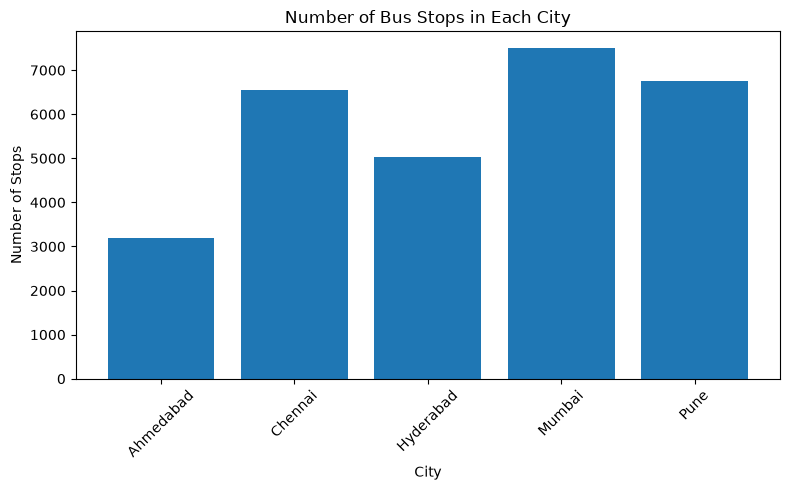

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    city_stop_counts["city"],
    city_stop_counts["total_stops"]
)

plt.title("Number of Bus Stops in Each City")
plt.xlabel("City")
plt.ylabel("Number of Stops")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
import pandas as pd

data_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\raw"
)

cities = [
    "ahmedabad",
    "chennai",
    "hyderabad",
    "mumbai",
    "pune"
]

overlap_results = []

for city in cities:

    city_dir = data_dir / city

    routes = pd.read_csv(
        city_dir / "routes.txt",
        dtype=str
    )

    trips = pd.read_csv(
        city_dir / "trips.txt",
        dtype=str
    )

    stop_times = pd.read_csv(
        city_dir / "stop_times.txt",
        dtype=str
    )

    # Connect trips with their routes
    trip_routes = trips[["trip_id", "route_id"]]

    trip_stops = stop_times[
        ["trip_id", "stop_id"]
    ]

    route_stops = trip_stops.merge(
        trip_routes,
        on="trip_id",
        how="inner"
    )

    # Count how many different routes serve each stop
    shared_stops = (
        route_stops.groupby("stop_id")["route_id"]
        .nunique()
        .reset_index(name="routes_serving_stop")
    )

    shared_stops = shared_stops[
        shared_stops["routes_serving_stop"] > 1
    ]

    shared_stops["city"] = city.title()

    overlap_results.append(shared_stops)

    print(
        f"{city.title()}: "
        f"{len(shared_stops)} stops served by multiple routes"
    )

overlap_df = pd.concat(
    overlap_results,
    ignore_index=True
)

print("\nTotal shared-stop records:", len(overlap_df))

Ahmedabad: 2690 stops served by multiple routes
Chennai: 5013 stops served by multiple routes
Hyderabad: 3863 stops served by multiple routes
Mumbai: 4492 stops served by multiple routes
Pune: 3662 stops served by multiple routes

Total shared-stop records: 19720


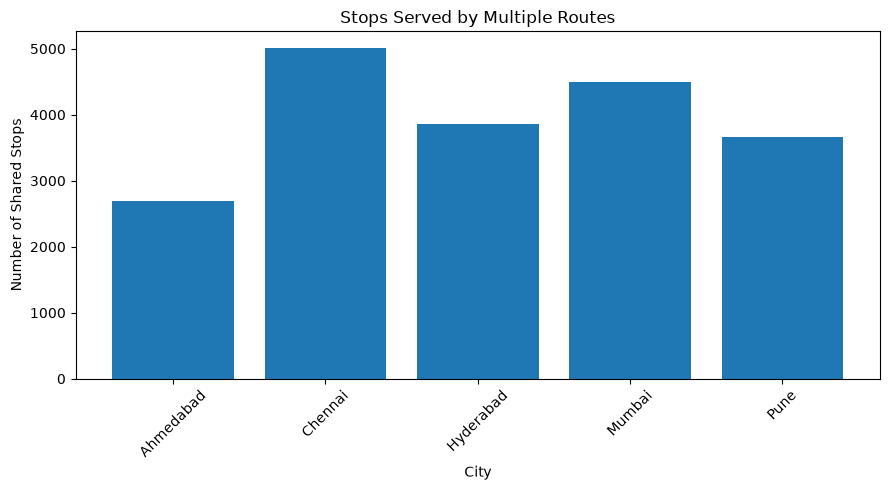

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    overlap_df["city"].drop_duplicates(),
    [2690, 5013, 3863, 4492, 3662]
)

plt.title("Stops Served by Multiple Routes")
plt.xlabel("City")
plt.ylabel("Number of Shared Stops")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()



The shared-stop analysis identified 19,720 city-stop records served by multiple routes across the five cities. Chennai had the highest number of shared stops (5,013), while Ahmedabad had the lowest (2,690). These findings indicate potential geographical overlap between public transport routes. However, shared stops do not confirm that routes follow the same path or are inefficient. Further analysis using route shapes and passenger demand data would be required to support stronger conclusions.

In [ ]:
from pathlib import Path
import pandas as pd

project_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
)

processed_dir = project_dir / "data" / "processed"

for file in processed_dir.glob("*.csv"):
    print(file.name)

ahmedabad_trips_by_route_hour.csv
ahmedabad_trip_headway_features.csv
ahmedabad_trip_time_features.csv
chennai_trips_by_route_hour.csv
chennai_trip_headway_features.csv
chennai_trip_time_features.csv
consolidated_data_quality_report.csv
feature_dictionary.csv
headway_validation_report.csv
hyderabad_trips_by_route_hour.csv
hyderabad_trip_headway_features.csv
hyderabad_trip_time_features.csv
missing_values_by_column_report.csv
mumbai_trips_by_route_hour.csv
mumbai_trip_headway_features.csv
mumbai_trip_time_features.csv
operating_days_summary.csv
pune_trips_by_route_hour.csv
pune_trip_headway_features.csv
pune_trip_time_features.csv
routes_without_trips.csv
routes_without_trips_source_check.csv
route_features.csv
route_feature_coverage_report.csv
route_hourly_trip_counts.csv
route_profiles.csv
trips_by_route_hour.csv


In [ ]:
import pandas as pd
from pathlib import Path

# Load the route features dataset
file_path = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker"
    r"\data\processed\route_features.csv"
)

route_df = pd.read_csv(file_path)

# Check dataset structure
print("Dataset shape:", route_df.shape)

print("\nColumn names:")
print(route_df.columns.tolist())

print("\nData types:")
print(route_df.dtypes)

print("\nFirst 5 rows:")
display(route_df.head())

Dataset shape: (8322, 20)

Column names:
['route_id', 'route_short_name', 'route_long_name', 'route_type', 'scheduled_trip_count', 'stop_count', 'estimated_straight_line_route_km', 'trips_with_distance', 'operates_monday', 'operates_tuesday', 'operates_wednesday', 'operates_thursday', 'operates_friday', 'operates_saturday', 'operates_sunday', 'operating_day_count', 'city', 'start_service_hour', 'end_service_hour', 'trips_with_valid_departure']

Data types:
route_id                                str
route_short_name                        str
route_long_name                         str
route_type                            int64
scheduled_trip_count                  int64
stop_count                            int64
estimated_straight_line_route_km    float64
trips_with_distance                 float64
operates_monday                     float64
operates_tuesday                    float64
operates_wednesday                  float64
operates_thursday                   float64
operates_fr

,route_id,route_short_name,route_long_name,route_type,scheduled_trip_count,stop_count,estimated_straight_line_route_km,trips_with_distance,operates_monday,operates_tuesday,operates_wednesday,operates_thursday,operates_friday,operates_saturday,operates_sunday,operating_day_count,city,start_service_hour,end_service_hour,trips_with_valid_departure
0,101sh,101sh,P.D.P.U. Cross Road ⇆ Asarva Railway Station,3,10,44,44.528570,10.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,6.0,19.0,10
1,103-1,103,Bhakti Circle ⇆ Gujarat University,3,22,80,22.365598,22.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,6.0,21.0,22
2,103-2,103,Bhakti Circle ⇆ Sarangpur,3,14,52,14.922204,14.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,5.0,23.0,14
3,103-3,103,Gujarat University ⇆ Sarangpur,3,6,28,8.947943,6.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,12.0,22.0,6
4,105,105,Naroda Industrial Township( MuthiyaGam ) ⇆ Lal...,3,216,40,63.726733,216.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,5.0,23.0,216


,route_type,scheduled_trip_count,stop_count,estimated_straight_line_route_km,trips_with_distance,operating_day_count,start_service_hour,end_service_hour,trips_with_valid_departure
route_type,1.00,0.10,0.10,-0.38,0.12,0.55,-0.28,0.20,0.10
scheduled_trip_count,0.10,1.00,0.40,-0.11,1.00,0.07,-0.30,0.26,1.00
stop_count,0.10,0.40,1.00,0.29,0.38,0.08,-0.26,0.54,0.40
estimated_straight_line_route_km,-0.38,-0.11,0.29,1.00,-0.11,-0.24,0.05,0.17,-0.11
trips_with_distance,0.12,1.00,0.38,-0.11,1.00,0.07,-0.30,0.26,1.00
operating_day_count,0.55,0.07,0.08,-0.24,0.07,1.00,-0.17,0.11,0.07
start_service_hour,-0.28,-0.30,-0.26,0.05,-0.30,-0.17,1.00,0.00,-0.30
end_service_hour,0.20,0.26,0.54,0.17,0.26,0.11,0.00,1.00,0.26
trips_with_valid_departure,0.10,1.00,0.40,-0.11,1.00,0.07,-0.30,0.26,1.00


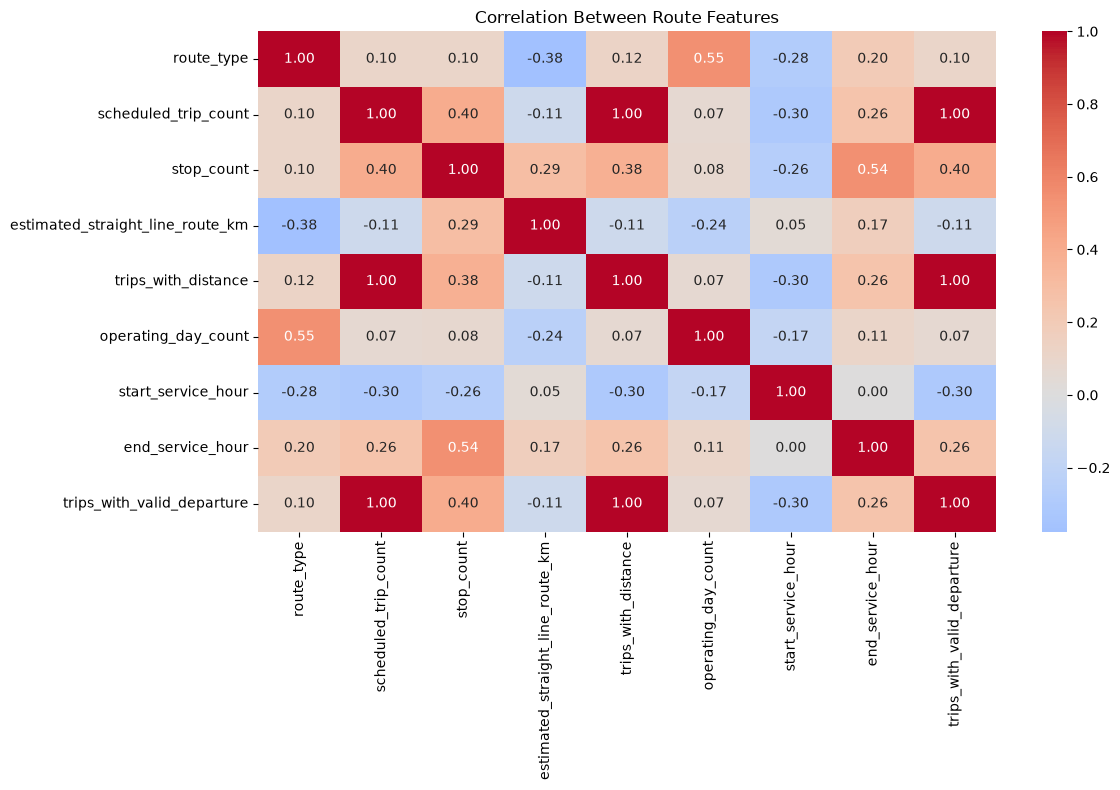

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Select numeric columns and exclude binary operating-day flags
numeric_df = route_df.select_dtypes(include="number").drop(
    columns=[
        "operates_monday",
        "operates_tuesday",
        "operates_wednesday",
        "operates_thursday",
        "operates_friday",
        "operates_saturday",
        "operates_sunday",
    ],
    errors="ignore"
)

correlation = numeric_df.corr()

display(correlation.round(2))

plt.figure(figsize=(12, 8))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Between Route Features")
plt.tight_layout()
plt.show()

In [ ]:
route_df[
    [
        "scheduled_trip_count",
        "trips_with_distance",
        "trips_with_valid_departure",
    ]
].describe()

,scheduled_trip_count,trips_with_distance,trips_with_valid_departure
count,8322.000000,7312.000000,8322.000000
mean,26.058399,29.657276,26.058399
std,75.377376,79.749215,75.377376
min,0.000000,1.000000,0.000000
25%,1.000000,1.000000,1.000000
50%,4.000000,5.000000,4.000000
75%,15.000000,20.000000,15.000000
max,2087.000000,2087.000000,2087.000000


In [ ]:
print(
    "Scheduled count equals valid departures:",
    route_df["scheduled_trip_count"].equals(
        route_df["trips_with_valid_departure"]
    )
)

valid = route_df[
    ["scheduled_trip_count", "trips_with_distance"]
].dropna()

print(
    "Scheduled count equals trips with distance on non-missing rows:",
    valid["scheduled_trip_count"].equals(valid["trips_with_distance"])
)

Scheduled count equals valid departures: True
Scheduled count equals trips with distance on non-missing rows: False


In [ ]:
valid = route_df[
    ["scheduled_trip_count", "trips_with_distance"]
].dropna().copy()

valid["difference"] = (
    valid["trips_with_distance"] - valid["scheduled_trip_count"]
)

print("Number of rows compared:", len(valid))
print("\nDifference counts:")
display(valid["difference"].value_counts().head(10))

print("\nAre all differences the same?")
print(valid["difference"].nunique() == 1)

print("\nCorrelation on non-missing rows:")
print(valid["scheduled_trip_count"].corr(valid["trips_with_distance"]))

Number of rows compared: 7312

Difference counts:


difference
0.0    7312
Name: count, dtype: int64


Are all differences the same?
True

Correlation on non-missing rows:
0.9999999999999998


,route_count,average_scheduled_trips,average_stop_count,average_route_distance_km
city,,,,
ahmedabad,639,22.41,40.27,24.83
chennai,5402,8.97,20.82,21.42
hyderabad,1031,43.54,63.86,25.95
mumbai,935,105.97,31.59,12.25
pune,315,32.15,82.09,20.54


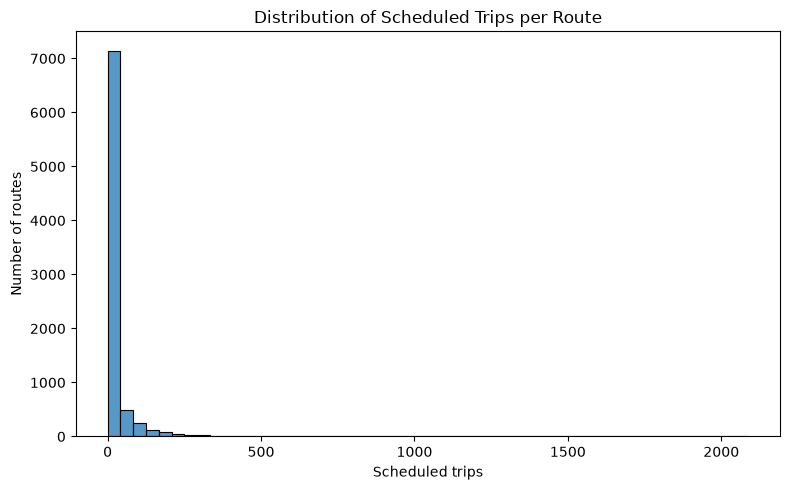

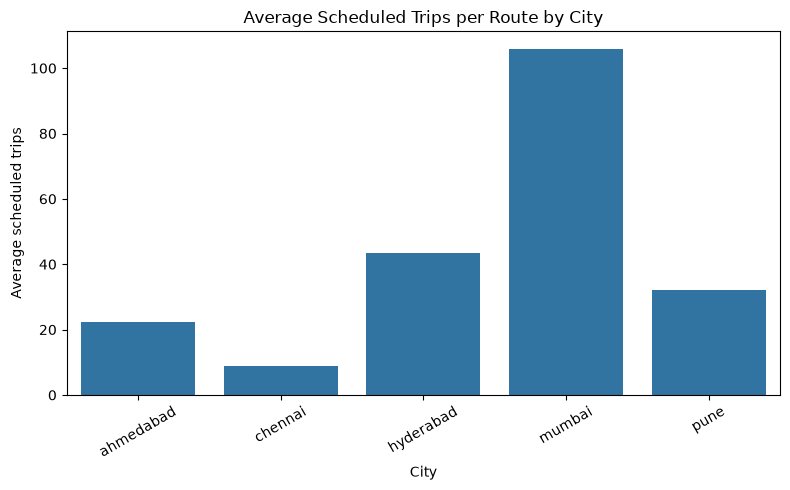

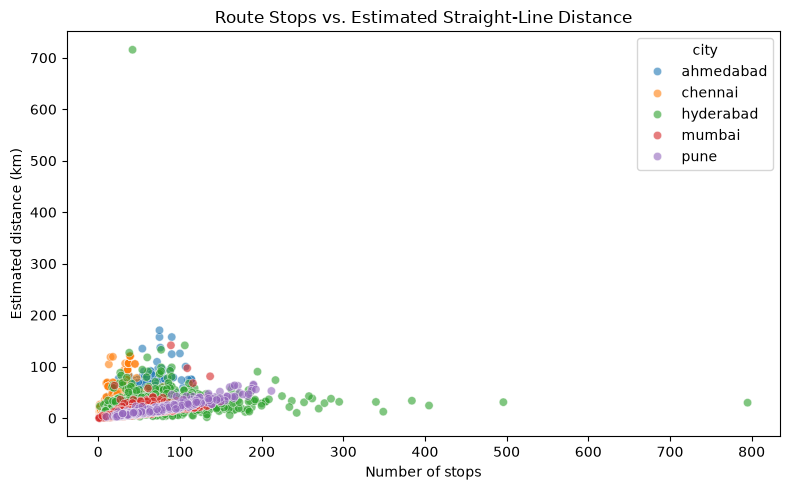

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Summary table by city
city_summary = (
    route_df.groupby("city")
    .agg(
        route_count=("route_id", "count"),
        average_scheduled_trips=("scheduled_trip_count", "mean"),
        average_stop_count=("stop_count", "mean"),
        average_route_distance_km=("estimated_straight_line_route_km", "mean")
    )
    .round(2)
)

display(city_summary)

# 1. Scheduled trips per route
plt.figure(figsize=(8, 5))
sns.histplot(route_df["scheduled_trip_count"], bins=50)
plt.title("Distribution of Scheduled Trips per Route")
plt.xlabel("Scheduled trips")
plt.ylabel("Number of routes")
plt.tight_layout()
plt.show()

# 2. Average scheduled trips by city
plt.figure(figsize=(8, 5))
sns.barplot(
    data=route_df,
    x="city",
    y="scheduled_trip_count",
    estimator="mean",
    errorbar=None
)
plt.title("Average Scheduled Trips per Route by City")
plt.xlabel("City")
plt.ylabel("Average scheduled trips")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 3. Stops compared with estimated route distance
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=route_df,
    x="stop_count",
    y="estimated_straight_line_route_km",
    hue="city",
    alpha=0.6
)
plt.title("Route Stops vs. Estimated Straight-Line Distance")
plt.xlabel("Number of stops")
plt.ylabel("Estimated distance (km)")
plt.tight_layout()
plt.show()

The EDA compared route-level service features across Ahmedabad, Chennai, Hyderabad, Mumbai, and Pune. The city summary and plots show differences in scheduled service levels, route stop counts, and estimated route distances. The trip-count distribution should be interpreted carefully because a small number of routes may have very high scheduled trip counts. The distance values are straight-line estimates, not actual road distances.

In [ ]:
from pathlib import Path
import pandas as pd

project_dir = Path(r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker")
processed_dir = project_dir / "data" / "processed"

hourly_file = processed_dir / "route_hourly_trip_counts.csv"

hourly_df = pd.read_csv(hourly_file)

print("Shape:", hourly_df.shape)
print("Columns:", hourly_df.columns.tolist())
display(hourly_df.head())

Shape: (50442, 4)
Columns: ['city', 'route_id', 'service_hour', 'scheduled_trip_count']


,city,route_id,service_hour,scheduled_trip_count
0,ahmedabad,101-C,6,7
1,ahmedabad,101-C,7,10
2,ahmedabad,101-C,8,9
3,ahmedabad,101-C,9,7
4,ahmedabad,101-C,10,6


In [ ]:
# Total scheduled trips by hour, across all cities
hourly_summary = (
    hourly_df.groupby("service_hour", as_index=False)["scheduled_trip_count"]
    .sum()
    .sort_values("service_hour")
)

display(hourly_summary)

# Compare broad time periods
def get_time_period(hour):
    if 5 <= hour < 12:
        return "Morning (5–11)"
    elif 12 <= hour < 17:
        return "Afternoon (12–16)"
    elif 17 <= hour < 21:
        return "Evening (17–20)"
    else:
        return "Night / early morning"

hourly_df["time_period"] = hourly_df["service_hour"].apply(get_time_period)

period_summary = (
    hourly_df.groupby("time_period", as_index=False)["scheduled_trip_count"]
    .sum()
    .sort_values("scheduled_trip_count", ascending=False)
)

display(period_summary)

,service_hour,scheduled_trip_count
0,0,1245
1,1,622
2,2,236
3,3,387
4,4,1970
5,5,6331
6,6,12603
7,7,14272
8,8,14228
9,9,13454


,time_period,scheduled_trip_count
2,Morning (5–11),86464
0,Afternoon (12–16),60976
1,Evening (17–20),46483
3,Night / early morning,22935


In [ ]:
# Keep the original GTFS service hour and derive the clock hour
hourly_df["clock_hour"] = hourly_df["service_hour"] % 24

# Combine extended GTFS hours with their matching clock hours
clock_hour_summary = (
    hourly_df.groupby("clock_hour", as_index=False)["scheduled_trip_count"]
    .sum()
    .sort_values("clock_hour")
)

display(clock_hour_summary)

# Group by time of day using the converted clock hour
def get_time_period(hour):
    if 5 <= hour < 12:
        return "Morning (5–11)"
    elif 12 <= hour < 17:
        return "Afternoon (12–16)"
    elif 17 <= hour < 21:
        return "Evening (17–20)"
    else:
        return "Night / early morning"

hourly_df["time_period"] = hourly_df["clock_hour"].apply(get_time_period)

period_summary = (
    hourly_df.groupby("time_period", as_index=False)["scheduled_trip_count"]
    .sum()
    .sort_values("scheduled_trip_count", ascending=False)
)

display(period_summary)

,clock_hour,scheduled_trip_count
0,0,1267
1,1,635
2,2,246
3,3,395
4,4,2077
5,5,6596
6,6,12905
7,7,14564
8,8,14508
9,9,13738


,time_period,scheduled_trip_count
2,Morning (5–11),88210
0,Afternoon (12–16),61010
1,Evening (17–20),46485
3,Night / early morning,21153


In [ ]:
from pathlib import Path
import pandas as pd

for file in project_dir.rglob("*.csv"):
    if file.name.lower() in {"trips.csv", "calendar.csv", "calendar_dates.csv"}:
        print(f"\nFILE: {file}")
        df = pd.read_csv(file, nrows=3)
        print("Columns:", df.columns.tolist())
        display(df.head(3))


FILE: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\ahmedabad\calendar.csv
Columns: ['service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date']


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,"1,2,3,4,5,6,7",1,1,1,1,1,1,1,20260930,20270329



FILE: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\ahmedabad\trips.csv
Columns: ['route_id', 'service_id', 'trip_id', 'trip_headsign', 'direction_id', 'shape_id']


,route_id,service_id,trip_id,trip_headsign,direction_id,shape_id
0,101sh,"1,2,3,4,5,6,7",AMC_9348910,Asarva Railway Station,1,NaN
1,101sh,"1,2,3,4,5,6,7",AMC_9348912,Asarva Railway Station,1,NaN
2,101sh,"1,2,3,4,5,6,7",AMC_9348914,Asarva Railway Station,1,NaN



FILE: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\chennai\calendar.csv
Columns: ['service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date']


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,MTC-Regular,1,1,1,1,1,1,1,20240501,20300501
1,MTC-Weekend,0,0,0,0,0,1,1,20240501,20300501
2,MTC-Hybrid,0,0,0,1,1,0,1,20240501,20300501


... (30 outputs left out)


FILE: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\cleaned\pune\calendar.csv
Columns: ['service_id', 'monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday', 'start_date', 'end_date']


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,WEEKDAY,1,1,1,1,1,1,1,20261007,20270405



FILE: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\cleaned\pune\trips.csv
Columns: ['route_id', 'service_id', 'trip_id', 'trip_headsign', 'direction_id', 'shape_id']


,route_id,service_id,trip_id,trip_headsign,direction_id,shape_id
0,108,WEEKDAY,trip_18_0,Sutardara,0,18
1,108,WEEKDAY,trip_18_1,Sutardara,0,18
2,108,WEEKDAY,trip_18_2,Sutardara,0,18


In [ ]:
from pathlib import Path
import pandas as pd

project_dir = Path(r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker")
processed_dir = project_dir / "data" / "processed"

for city_dir in sorted(processed_dir.iterdir()):
    if not city_dir.is_dir():
        continue

    trips_file = city_dir / "trips.csv"
    calendar_file = city_dir / "calendar.csv"

    if not trips_file.exists() or not calendar_file.exists():
        continue

    trips = pd.read_csv(trips_file, dtype={"service_id": str})
    calendar = pd.read_csv(calendar_file, dtype={"service_id": str})

    print(f"\n--- {city_dir.name.upper()} ---")
    print("Trip service IDs:")
    print(trips["service_id"].value_counts().head(10))

    print("Calendar service IDs and weekday flags:")
    display(calendar[
        ["service_id", "monday", "tuesday", "wednesday",
         "thursday", "friday", "saturday", "sunday"]
    ].head(15))


--- AHMEDABAD ---
Trip service IDs:
service_id
1,2,3,4,5,6,7    14323
Name: count, dtype: int64
Calendar service IDs and weekday flags:


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday
0,"1,2,3,4,5,6,7",1,1,1,1,1,1,1



--- CHENNAI ---
Trip service IDs:
service_id
MTC-Regular            46973
CMRL-WD                  625
SRR-service_1111111      384
SRR-service_1111110      199
SRR-service_0000001      180
MTC-HSC                   74
Name: count, dtype: int64
Calendar service IDs and weekday flags:


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday
0,MTC-Regular,1,1,1,1,1,1,1
1,MTC-Weekend,0,0,0,0,0,1,1
2,MTC-Hybrid,0,0,0,1,1,0,1
3,MTC-HSC,1,1,1,1,1,1,0
4,MTC-test,1,1,1,0,0,0,0
5,MTC-'/><script>alert(1)</script>,1,0,0,0,0,0,0
6,CMRL-WD,1,1,1,1,1,1,0
7,SRR-service_1111111,1,1,1,1,1,1,1
8,SRR-service_1111110,1,1,1,1,1,1,0
9,SRR-service_0000001,0,0,0,0,0,0,1



--- HYDERABAD ---
Trip service IDs:
service_id
MTWTFSS    44892
Name: count, dtype: int64
Calendar service IDs and weekday flags:


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday
0,MTWTFSS,1,1,1,1,1,1,1



--- MUMBAI ---
Trip service IDs:
service_id
1,2,3,4,5,6,7    99080
Name: count, dtype: int64
Calendar service IDs and weekday flags:


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday
0,"1,2,3,4,5,6,7",1,1,1,1,1,1,1



--- PUNE ---
Trip service IDs:
service_id
WEEKDAY    10128
Name: count, dtype: int64
Calendar service IDs and weekday flags:


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday
0,WEEKDAY,1,1,1,1,1,1,1


In [ ]:
from pathlib import Path
import pandas as pd

city_dir = Path(
    r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\chennai"
)

trips = pd.read_csv(city_dir / "trips.csv", dtype={"service_id": str})
calendar = pd.read_csv(city_dir / "calendar.csv", dtype={"service_id": str})

# Count scheduled trips assigned to each calendar service
service_counts = (
    trips.groupby("service_id")
    .size()
    .rename("trip_count")
    .reset_index()
)

service_days = service_counts.merge(calendar, on="service_id", how="left")

display(service_days[
    ["service_id", "trip_count", "monday", "tuesday", "wednesday",
     "thursday", "friday", "saturday", "sunday"]
].sort_values("trip_count", ascending=False))

,service_id,trip_count,monday,tuesday,wednesday,thursday,friday,saturday,sunday
2,MTC-Regular,46973,1,1,1,1,1,1,1
0,CMRL-WD,625,1,1,1,1,1,1,0
5,SRR-service_1111111,384,1,1,1,1,1,1,1
4,SRR-service_1111110,199,1,1,1,1,1,1,0
3,SRR-service_0000001,180,0,0,0,0,0,0,1
1,MTC-HSC,74,1,1,1,1,1,1,0


In [ ]:
# service_days is the merged Chennai table from your previous cell

day_columns = [
    "monday", "tuesday", "wednesday", "thursday",
    "friday", "saturday", "sunday"
]

# Check whether every trip service matched a calendar entry
print("Calendar flags missing:", service_days[day_columns].isna().any(axis=1).sum())

# Scheduled trips active on each day
daily_totals = {
    day: (service_days["trip_count"] * service_days[day]).sum()
    for day in day_columns
}

daily_summary = pd.DataFrame({
    "day": list(daily_totals.keys()),
    "scheduled_trip_count": list(daily_totals.values())
})

display(daily_summary)

weekday_average = daily_summary.loc[
    daily_summary["day"].isin(day_columns[:5]), "scheduled_trip_count"
].mean()

weekend_average = daily_summary.loc[
    daily_summary["day"].isin(day_columns[5:]), "scheduled_trip_count"
].mean()

print("Average scheduled trips per weekday:", round(weekday_average))
print("Average scheduled trips per weekend day:", round(weekend_average))

Calendar flags missing: 0


,day,scheduled_trip_count
0,monday,48255
1,tuesday,48255
2,wednesday,48255
3,thursday,48255
4,friday,48255
5,saturday,48255
6,sunday,47537


Average scheduled trips per weekday: 48255
Average scheduled trips per weekend day: 47896


In [ ]:
from pathlib import Path
import pandas as pd

project_dir = Path(r"C:\Users\LENOVO\OneDrive\Desktop\RouteRanker")
features_file = project_dir / "data" / "processed" / "route_features.csv"

route_df = pd.read_csv(features_file)

print("Shape:", route_df.shape)
print("Columns:")
print(route_df.columns.tolist())
route_df.head()

Shape: (8322, 20)
Columns:
['route_id', 'route_short_name', 'route_long_name', 'route_type', 'scheduled_trip_count', 'stop_count', 'estimated_straight_line_route_km', 'trips_with_distance', 'operates_monday', 'operates_tuesday', 'operates_wednesday', 'operates_thursday', 'operates_friday', 'operates_saturday', 'operates_sunday', 'operating_day_count', 'city', 'start_service_hour', 'end_service_hour', 'trips_with_valid_departure']


,route_id,route_short_name,route_long_name,route_type,scheduled_trip_count,stop_count,estimated_straight_line_route_km,trips_with_distance,operates_monday,operates_tuesday,operates_wednesday,operates_thursday,operates_friday,operates_saturday,operates_sunday,operating_day_count,city,start_service_hour,end_service_hour,trips_with_valid_departure
0,101sh,101sh,P.D.P.U. Cross Road ⇆ Asarva Railway Station,3,10,44,44.528570,10.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,6.0,19.0,10
1,103-1,103,Bhakti Circle ⇆ Gujarat University,3,22,80,22.365598,22.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,6.0,21.0,22
2,103-2,103,Bhakti Circle ⇆ Sarangpur,3,14,52,14.922204,14.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,5.0,23.0,14
3,103-3,103,Gujarat University ⇆ Sarangpur,3,6,28,8.947943,6.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,12.0,22.0,6
4,105,105,Naroda Industrial Township( MuthiyaGam ) ⇆ Lal...,3,216,40,63.726733,216.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,7.0,ahmedabad,5.0,23.0,216


In [ ]:
# Top 5 routes by scheduled trips in each city
top_routes = (
    route_df.sort_values(
        ["city", "scheduled_trip_count"],
        ascending=[True, False]
    )
    .groupby("city")
    .head(5)
)

print("Top 5 routes by scheduled trips:")
display(
    top_routes[
        ["city", "route_id", "route_short_name",
         "scheduled_trip_count", "stop_count",
         "estimated_straight_line_route_km"]
    ]
)

# Bottom 5 routes by scheduled trips in each city
bottom_routes = (
    route_df.sort_values(
        ["city", "scheduled_trip_count"],
        ascending=[True, True]
    )
    .groupby("city")
    .head(5)
)

print("Bottom 5 routes by scheduled trips:")
display(
    bottom_routes[
        ["city", "route_id", "route_short_name",
         "scheduled_trip_count", "stop_count",
         "estimated_straight_line_route_km"]
    ]
)

Top 5 routes by scheduled trips:


,city,route_id,route_short_name,scheduled_trip_count,stop_count,estimated_straight_line_route_km
143,ahmedabad,401-1,401,217,50,27.886452
4,ahmedabad,105,105,216,40,63.726733
30,ahmedabad,127-1,127,168,48,14.100303
81,ahmedabad,150-1,150,156,70,25.345527
253,ahmedabad,71/1sh-1,71/1sh,152,64,25.586013
3047,chennai,MTC-20163,25 R,210,33,23.307087
3059,chennai,MTC-20167,25 R1,208,37,22.497611
1898,chennai,MTC-24072,91,202,36,28.020023
1906,chennai,MTC-24073,91 R,202,35,27.741785
1014,chennai,MTC-20578,57 R1,197,25,15.936197


Bottom 5 routes by scheduled trips:


,city,route_id,route_short_name,scheduled_trip_count,stop_count,estimated_straight_line_route_km
626,ahmedabad,Kalol To Pathikashram Via Sardhav,Kalol To Pathikashram Via Sardhav,0,0,NaN
627,ahmedabad,Mansa To Pathikashram,Mansa To Pathikashram,0,0,NaN
631,ahmedabad,Pathikashram To Kalol Via Sardhav,Pathikashram To Kalol Via Sardhav,0,0,NaN
632,ahmedabad,Pathikashram To Mansa,Pathikashram To Mansa,0,0,NaN
634,ahmedabad,Pathikashram To Pundhara,Pathikashram To Pundhara,0,0,NaN
648,chennai,MTC-18761,T23C CT,0,0,NaN
650,chennai,MTC-11919,55K,0,0,NaN
655,chennai,MTC-18763,T23C CT1,0,0,NaN
658,chennai,MTC-13402,S43,0,0,NaN
680,chennai,MTC-17678,549,0,0,NaN


In [ ]:
# Summarize scheduled-trip counts by city
trip_summary = (
    route_df.groupby("city")
    .agg(
        total_route_records=("route_id", "size"),
        missing_trip_count=("scheduled_trip_count", lambda s: s.isna().sum()),
        zero_trip_count=("scheduled_trip_count", lambda s: s.eq(0).sum()),
        routes_with_trips=("scheduled_trip_count", lambda s: s.gt(0).sum())
    )
    .reset_index()
)

display(trip_summary)

,city,total_route_records,missing_trip_count,zero_trip_count,routes_with_trips
0,ahmedabad,639,0,6,633
1,chennai,5402,0,677,4725
2,hyderabad,1031,0,0,1031
3,mumbai,935,0,323,612
4,pune,315,0,0,315


In [ ]:
# Check trip-count outliers separately for each city
outlier_rows = []

for city, group in route_df.groupby("city"):
    trips = group["scheduled_trip_count"].dropna()

    q1 = trips.quantile(0.25)
    q3 = trips.quantile(0.75)
    iqr = q3 - q1

    lower_limit = q1 - 1.5 * iqr
    upper_limit = q3 + 1.5 * iqr

    city_outliers = group[
        (group["scheduled_trip_count"] < lower_limit) |
        (group["scheduled_trip_count"] > upper_limit)
    ].copy()

    city_outliers["lower_limit"] = lower_limit
    city_outliers["upper_limit"] = upper_limit
    outlier_rows.append(city_outliers)

outliers = pd.concat(outlier_rows, ignore_index=True)

print("Outlier routes by city:")
display(
    outliers.groupby("city")
    .size()
    .reset_index(name="outlier_route_count")
)

print("Example outlier routes:")
display(
    outliers[
        ["city", "route_id", "scheduled_trip_count",
         "stop_count", "estimated_straight_line_route_km",
         "lower_limit", "upper_limit"]
    ].head(20)
)

Outlier routes by city:


,city,outlier_route_count
0,ahmedabad,76
1,chennai,699
2,hyderabad,138
3,mumbai,58
4,pune,2


Example outlier routes:


,city,route_id,scheduled_trip_count,stop_count,estimated_straight_line_route_km,lower_limit,upper_limit
0,ahmedabad,105,216,40,63.726733,-26.0,54.0
1,ahmedabad,123sh-1,123,38,27.856299,-26.0,54.0
2,ahmedabad,125/2,64,34,22.157497,-26.0,54.0
3,ahmedabad,127-1,168,48,14.100303,-26.0,54.0
4,ahmedabad,13/1-1,128,59,16.765452,-26.0,54.0
5,ahmedabad,130sh-1,108,54,24.403282,-26.0,54.0
6,ahmedabad,135-1,120,53,51.460553,-26.0,54.0
7,ahmedabad,137sh-1,64,52,45.999645,-26.0,54.0
8,ahmedabad,142sh-1,130,40,12.117960,-26.0,54.0
9,ahmedabad,144-1,80,58,17.579928,-26.0,54.0


In [ ]:
from pathlib import Path
import pandas as pd

processed_dir = project_dir / "data" / "processed"

for city in ["ahmedabad", "chennai", "hyderabad", "mumbai", "pune"]:
    stop_files = list(processed_dir.rglob("stops.csv"))
    city_files = [p for p in stop_files if city in str(p).lower()]

    print(f"\n{city}:")
    if not city_files:
        print("No processed stops.csv found")
        continue

    stops = pd.read_csv(city_files[0])
    print("File:", city_files[0])
    print("Columns:", stops.columns.tolist())


ahmedabad:
File: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\ahmedabad\stops.csv
Columns: ['stop_id', 'stop_name', 'stop_lat', 'stop_lon']

chennai:
File: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\chennai\stops.csv
Columns: ['stop_id', 'stop_name', 'stop_lat', 'stop_lon', 'stop_desc', 'zone_id', 'location_type', 'parent_station', 'platform_code', 'stop_code']

hyderabad:
File: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\hyderabad\stops.csv
Columns: ['stop_id', 'stop_name', 'zone_id', 'stop_lat', 'stop_lon', 'stop_desc']

mumbai:
File: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\mumbai\stops.csv
Columns: ['stop_id', 'stop_name', 'stop_lat', 'stop_lon']

pune:
File: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\data\processed\pune\stops.csv
Columns: ['stop_id', 'stop_name', 'stop_lat', 'stop_lon']


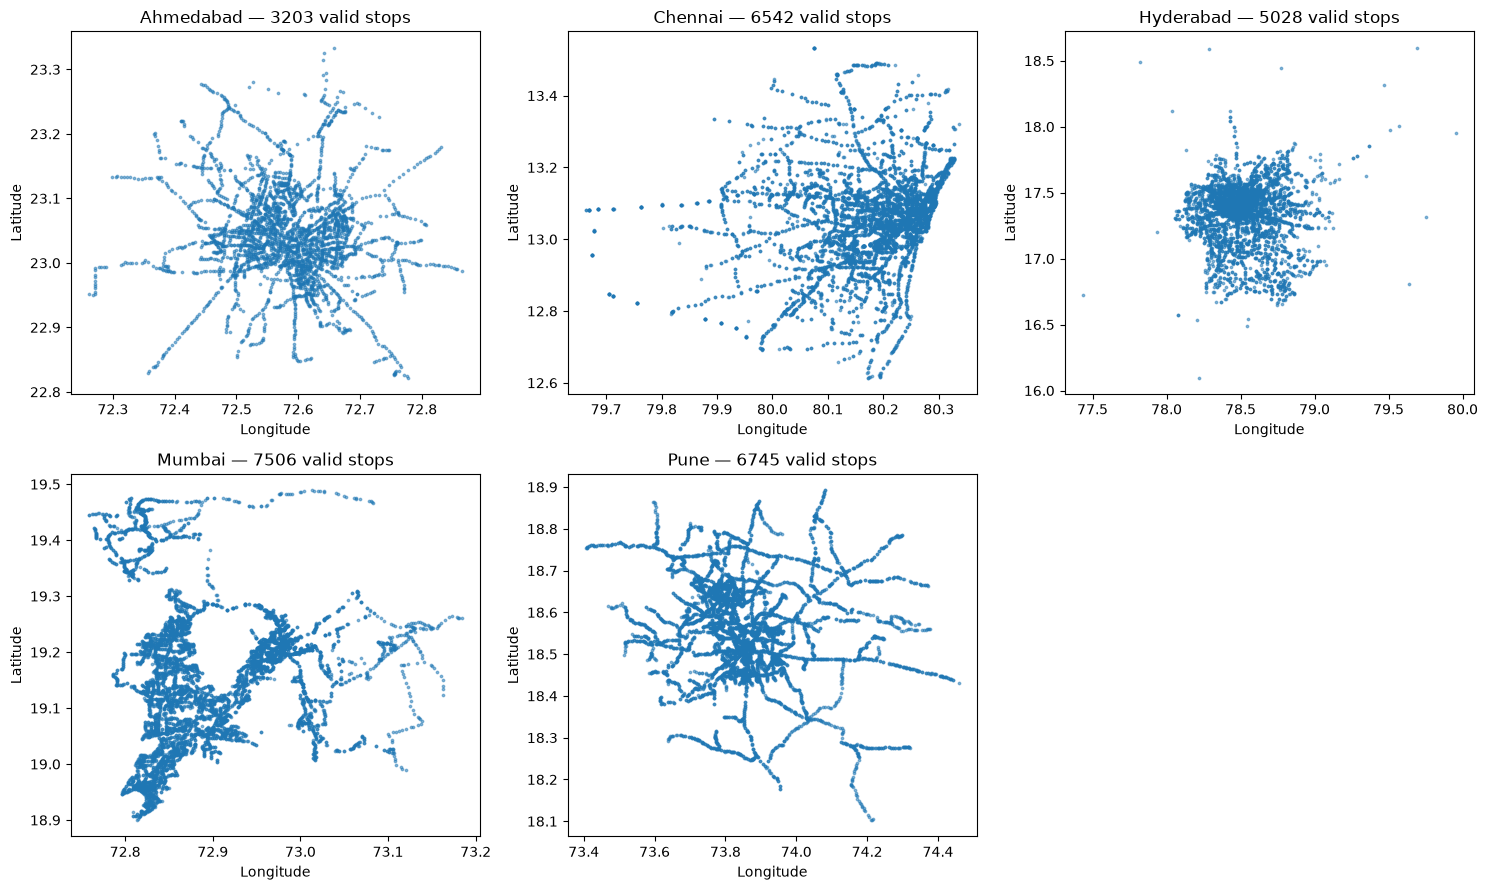

Saved: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module3_stop_location_map.png


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

processed_dir = project_dir / "data" / "processed"
reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

cities = ["ahmedabad", "chennai", "hyderabad", "mumbai", "pune"]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, city in enumerate(cities):
    stops_file = processed_dir / city / "stops.csv"
    stops = pd.read_csv(stops_file)

    # Keep rows with valid coordinates
    stops["stop_lat"] = pd.to_numeric(stops["stop_lat"], errors="coerce")
    stops["stop_lon"] = pd.to_numeric(stops["stop_lon"], errors="coerce")

    valid = stops[
        stops["stop_lat"].between(-90, 90) &
        stops["stop_lon"].between(-180, 180)
    ]

    axes[i].scatter(valid["stop_lon"], valid["stop_lat"], s=3, alpha=0.5)
    axes[i].set_title(f"{city.title()} — {len(valid)} valid stops")
    axes[i].set_xlabel("Longitude")
    axes[i].set_ylabel("Latitude")

# Hide the unused sixth subplot
axes[-1].axis("off")

plt.tight_layout()
plt.savefig(reports_dir / "module3_stop_location_map.png", dpi=200)
plt.show()

print("Saved:", reports_dir / "module3_stop_location_map.png")

In [ ]:
from pathlib import Path

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

report_text = """
# RouteRanker — Module 3: Exploratory Data Analysis

## Objective
Explore the GTFS-based route and service indicators for Ahmedabad, Chennai,
Hyderabad, Mumbai, and Pune to understand scheduled service patterns and
identify data that may need further review.

## Route comparison
Routes differ in scheduled trip counts, stop counts, and estimated
straight-line distances. Comparisons should be made within each city because
the cities have different service scales and route records.

## Routes without scheduled trips
The route feature data contains:
- Ahmedabad: 6 routes with zero scheduled trips
- Chennai: 677 routes with zero scheduled trips
- Hyderabad: 0 routes with zero scheduled trips
- Mumbai: 323 routes with zero scheduled trips
- Pune: 0 routes with zero scheduled trips

These records should be reviewed against the source GTFS data. A route with
zero scheduled trips is not automatically an underused or inefficient route.

## Outlier screening
The IQR check flagged:
- Ahmedabad: 76 routes
- Chennai: 699 routes
- Hyderabad: 138 routes
- Mumbai: 58 routes
- Pune: 2 routes

These are statistical flags for further review, not confirmed errors or
inefficient routes.

## Stop-location exploration
Stop coordinates were available for all five cities. The saved plot
`module3_stop_location_map.png` shows stop locations by city. No `shapes.txt`
was found, so the current data supports plotting stop locations but not
drawing actual GTFS route paths.

## Interpretation limits
Scheduled trip counts describe the timetable data, not actual operated trips
or passenger demand. Estimated straight-line distance is not the road distance
or actual route length. These indicators should not be treated as direct
measures of overcrowding or route efficiency.

## Next step
Use the reviewed and documented route indicators as inputs for Module 4
preprocessing, while retaining the noted data limitations.
"""

report_path = reports_dir / "module3_eda_summary.md"
report_path.write_text(report_text.strip(), encoding="utf-8")

print("Saved report:", report_path)

Saved report: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module3_eda_summary.md


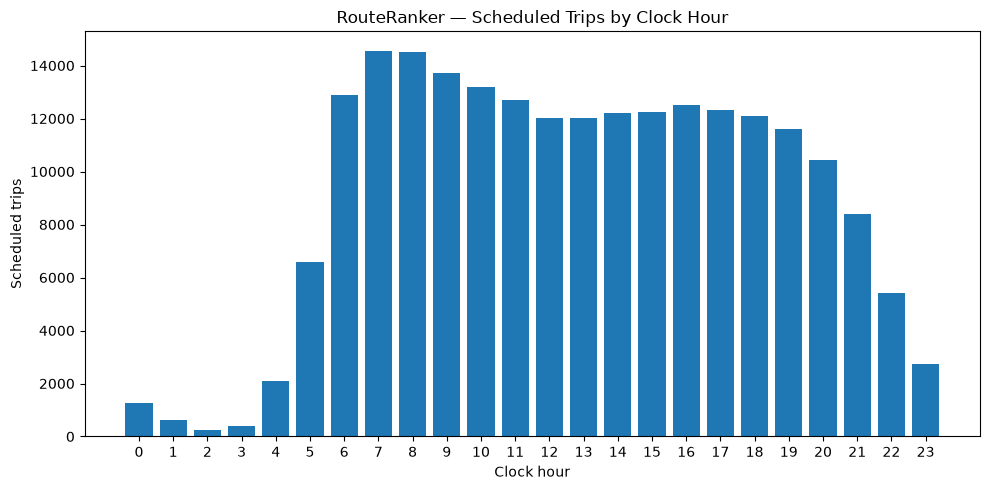

Updated report: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module3_eda_summary.md
Saved hourly chart: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\module3_hourly_trip_pattern.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Hourly scheduled-trip totals, grouped by clock hour (service_hour % 24)
hourly_counts = [
    1267, 635, 246, 395, 2077, 6596, 12905, 14564,
    14508, 13738, 13194, 12705, 12022, 12005, 12208,
    12264, 12511, 12328, 12092, 11620, 10445, 8391,
    5405, 2737
]

hourly_df = pd.DataFrame({
    "clock_hour": range(24),
    "scheduled_trips": hourly_counts
})

# Save hourly pattern chart
plt.figure(figsize=(10, 5))
plt.bar(hourly_df["clock_hour"], hourly_df["scheduled_trips"])
plt.xticks(range(24))
plt.xlabel("Clock hour")
plt.ylabel("Scheduled trips")
plt.title("RouteRanker — Scheduled Trips by Clock Hour")
plt.tight_layout()

hourly_chart_path = reports_dir / "module3_hourly_trip_pattern.png"
plt.savefig(hourly_chart_path, dpi=200)
plt.show()

# Append the findings to the existing report
report_path = reports_dir / "module3_eda_summary.md"

additional_findings = """

## Hourly service pattern
The hourly summary was grouped by clock hour using service hour modulo 24,
so GTFS service times after midnight are included in their corresponding
clock-hour group. The busiest clock hour in the combined summary was 07:00,
with 14,564 scheduled trips.

The reported time-period totals were:
- Morning (05:00–11:59): 88,210 scheduled trips
- Afternoon (12:00–16:59): 61,010 scheduled trips
- Evening (17:00–20:59): 46,485 scheduled trips
- Night/early morning (remaining hours): 21,153 scheduled trips

These totals represent scheduled service in the GTFS data, not passenger
demand or confirmed operated trips.

## Weekday/weekend comparison
For Chennai, the calendar-based summary showed an average of 48,255 scheduled
trips per weekday and 47,896 per weekend day. The weekend-day average was
359 trips lower (about 0.7%).

This comparison is based on calendar service assignments. It does not confirm
that trips operated as scheduled or measure passenger demand. Comparable
weekday/weekend findings were not established for the other cities in this
summary.

## Saved hourly chart
The hourly-pattern chart is saved as `module3_hourly_trip_pattern.png`.
"""

with report_path.open("a", encoding="utf-8") as f:
    f.write(additional_findings)

print("Updated report:", report_path)
print("Saved hourly chart:", hourly_chart_path)

In [ ]:
for file in [
    reports_dir / "module3_eda_summary.md",
    reports_dir / "module3_stop_location_map.png",
    reports_dir / "module3_hourly_trip_pattern.png"
]:
    print(f"{file.name}: {'Found' if file.exists() else 'MISSING'}")

module3_eda_summary.md: Found
module3_stop_location_map.png: Found
module3_hourly_trip_pattern.png: Found


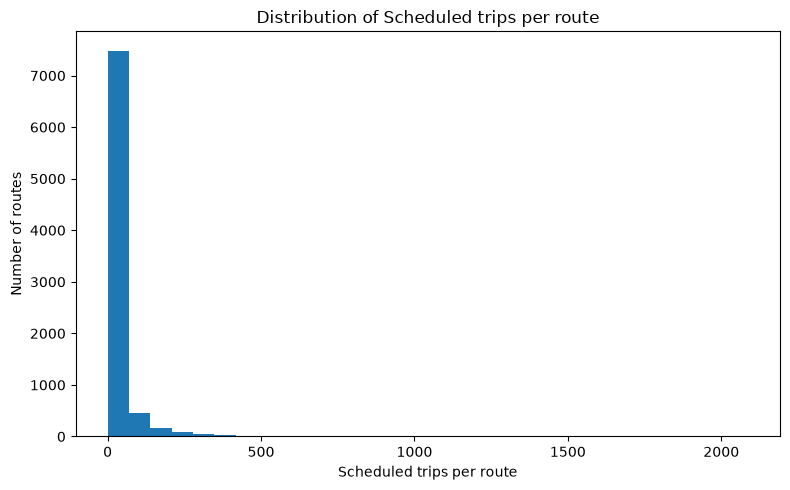

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_23972\332374554.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


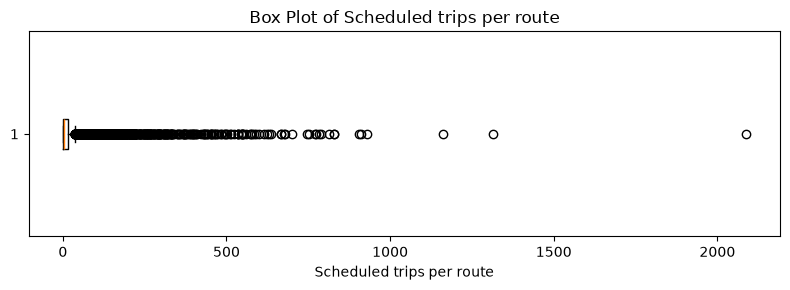

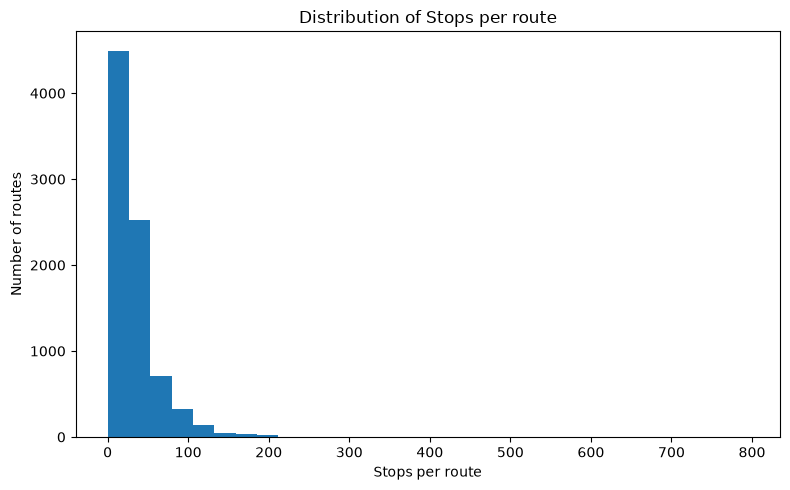

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_23972\332374554.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


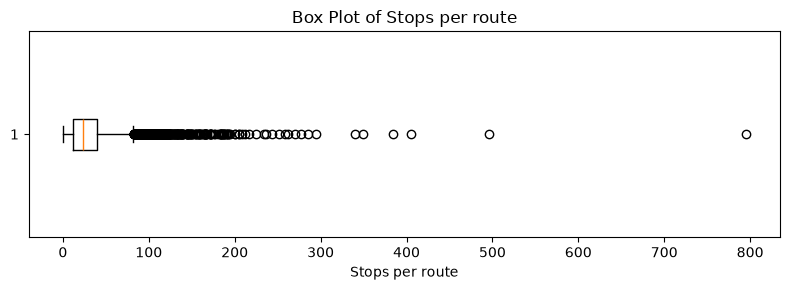

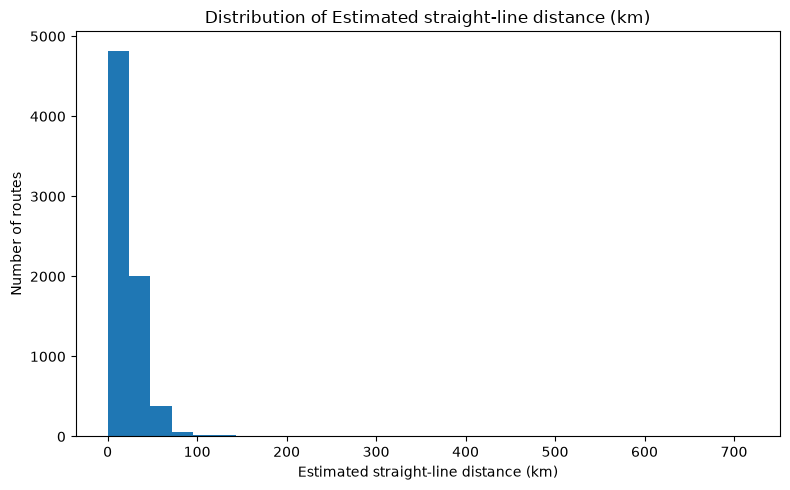

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_23972\332374554.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(values, vert=False)


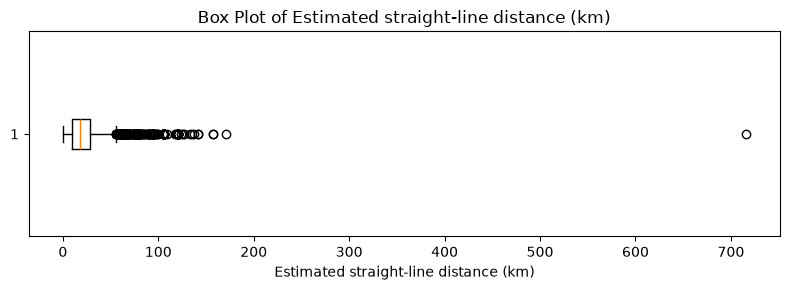

Saved feature-distribution charts in: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

features = {
    "scheduled_trip_count": "Scheduled trips per route",
    "stop_count": "Stops per route",
    "estimated_straight_line_route_km": "Estimated straight-line distance (km)"
}

for column, label in features.items():
    values = pd.to_numeric(route_df[column], errors="coerce").dropna()

    # Histogram
    plt.figure(figsize=(8, 5))
    plt.hist(values, bins=30)
    plt.title(f"Distribution of {label}")
    plt.xlabel(label)
    plt.ylabel("Number of routes")
    plt.tight_layout()
    plt.savefig(reports_dir / f"module3_{column}_histogram.png", dpi=200)
    plt.show()
    plt.close()

    # Box plot
    plt.figure(figsize=(8, 3))
    plt.boxplot(values, vert=False)
    plt.title(f"Box Plot of {label}")
    plt.xlabel(label)
    plt.tight_layout()
    plt.savefig(reports_dir / f"module3_{column}_boxplot.png", dpi=200)
    plt.show()
    plt.close()

print("Saved feature-distribution charts in:", reports_dir)

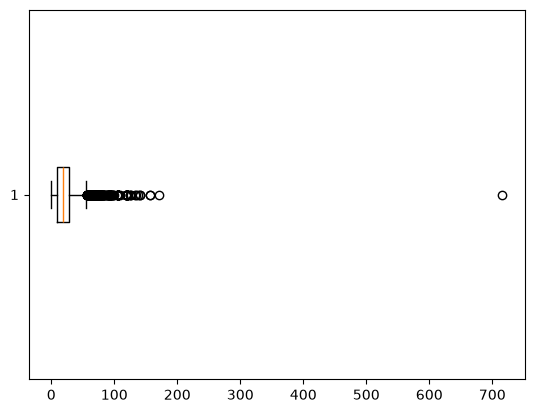

In [ ]:
_ = plt.boxplot(values, orientation="horizontal")

In [ ]:
from pathlib import Path
import pandas as pd

reports_dir = project_dir / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Keep only comparison columns that exist in the dataset
comparison_columns = [
    "city",
    "route_id",
    "route_short_name",
    "route_long_name",
    "scheduled_trip_count",
    "stop_count",
    "estimated_straight_line_route_km",
    "service_start_hour",
    "service_end_hour",
    "operating_days",
]

comparison_columns = [
    col for col in comparison_columns if col in route_df.columns
]

route_comparison = route_df[comparison_columns].copy()

# Sort by city and scheduled trips, if those columns are available
sort_columns = [
    col for col in ["city", "scheduled_trip_count"]
    if col in route_comparison.columns
]

if sort_columns:
    route_comparison = route_comparison.sort_values(
        sort_columns,
        ascending=[True, False][:len(sort_columns)]
    )

route_comparison_path = reports_dir / "route_comparison_summary.csv"
route_comparison.to_csv(route_comparison_path, index=False)

print("Saved:", route_comparison_path)
print("Rows and columns:", route_comparison.shape)
route_comparison.head()

Saved: C:\Users\LENOVO\OneDrive\Desktop\RouteRanker\reports\route_comparison_summary.csv
Rows and columns: (8322, 7)


,city,route_id,route_short_name,route_long_name,scheduled_trip_count,stop_count,estimated_straight_line_route_km
143,ahmedabad,401-1,401,Chandkheda (Sarthi Bunglows) ⇆ Vasna,217,50,27.886452
4,ahmedabad,105,105,Naroda Industrial Township( MuthiyaGam ) ⇆ Lal...,216,40,63.726733
30,ahmedabad,127-1,127,Bhakti Circle ⇆ Sarangpur,168,48,14.100303
81,ahmedabad,150-1,150,Chinubhainagar ⇆ Sarkhej Gam,156,70,25.345527
253,ahmedabad,71/1sh-1,71/1sh,Gandhinagar University ⇆ Lal Darwaja,152,64,25.586013


### Interpretation of Feature Distributions

The feature distribution charts show how scheduled service characteristics vary across routes. Scheduled trip counts indicate the number of trips listed in the timetable for each route. Differences between routes show variation in planned service levels; they do not, by themselves, indicate passenger demand or route efficiency.

The stop-count distribution shows how many distinct stops are associated with each route. Routes with more stops may serve a wider sequence of locations, but stop count alone does not describe route distance, travel time, or passenger use.

The estimated route-length distribution is based on the available calculated length feature. It should be treated as an estimate, not an exact road or route distance. Unusually high or low values are candidates for checking against the source data rather than automatic errors.

Box plots highlight values that are statistically unusual compared with the rest of the dataset. These flagged values are retained unless a separate data-quality check establishes that they are invalid.

### Interpretation of Route-Wise Comparisons

The route comparison summary shows that scheduled trip counts, stop counts, and available route-length estimates differ across routes. Routes with relatively high or low scheduled trip counts are useful candidates for further investigation, but these differences do not confirm that a route is efficient, inefficient, overcrowded, or underutilised.

A fair comparison should consider route length, operating hours, service days, timetable coverage, and the needs of the areas served. The available GTFS schedule data describes planned service. Passenger counts, occupancy, actual operating records, and local service context would be needed to support stronger conclusions.

### Geographic Analysis: Data Limitation

Stop latitude and longitude coordinates were available, so the map displays the geographic locations of stops. Route shape information was not available in the dataset; therefore, the map does not show the paths followed by buses.

The map can help inspect the distribution of stops, but it cannot confirm route paths, shared route segments, or geographical overlap between routes. Two routes serving the same stop are not necessarily redundant. Route-shape data and a suitable method for comparing route paths would be required for a reliable overlap analysis.